In [62]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
import time




bloco = 0
r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [63]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [64]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_watch_concat_by_comparacao_grupos.csv')

In [65]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,-0.309962
1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,-0.048972
2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,-0.195978
3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,-0.156563
4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,-0.001035


In [66]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [67]:
data = data[data["atividade"].isin([0,1,2,3])]

In [68]:
validation_set1=np.arange(1636,1641)
validation_set2=np.arange(1641,1646)
validation_set3=np.arange(1646,1651)
validation_set4=np.arange(1600,1605)
validation_set5=np.arange(1605,1610)
validation_set6=np.arange(1610,1615)
validation_set7=np.arange(1615,1620)
validation_set8=np.arange(1620,1625)
validation_set9=np.arange(1625,1631)
validation_set10=np.arange(1631,1636)
combined_validation_sets = [validation_set1, validation_set2, validation_set3, validation_set4,
validation_set5,validation_set6,validation_set7,validation_set8,validation_set9,validation_set10]

imprimindo tamanho do set 5


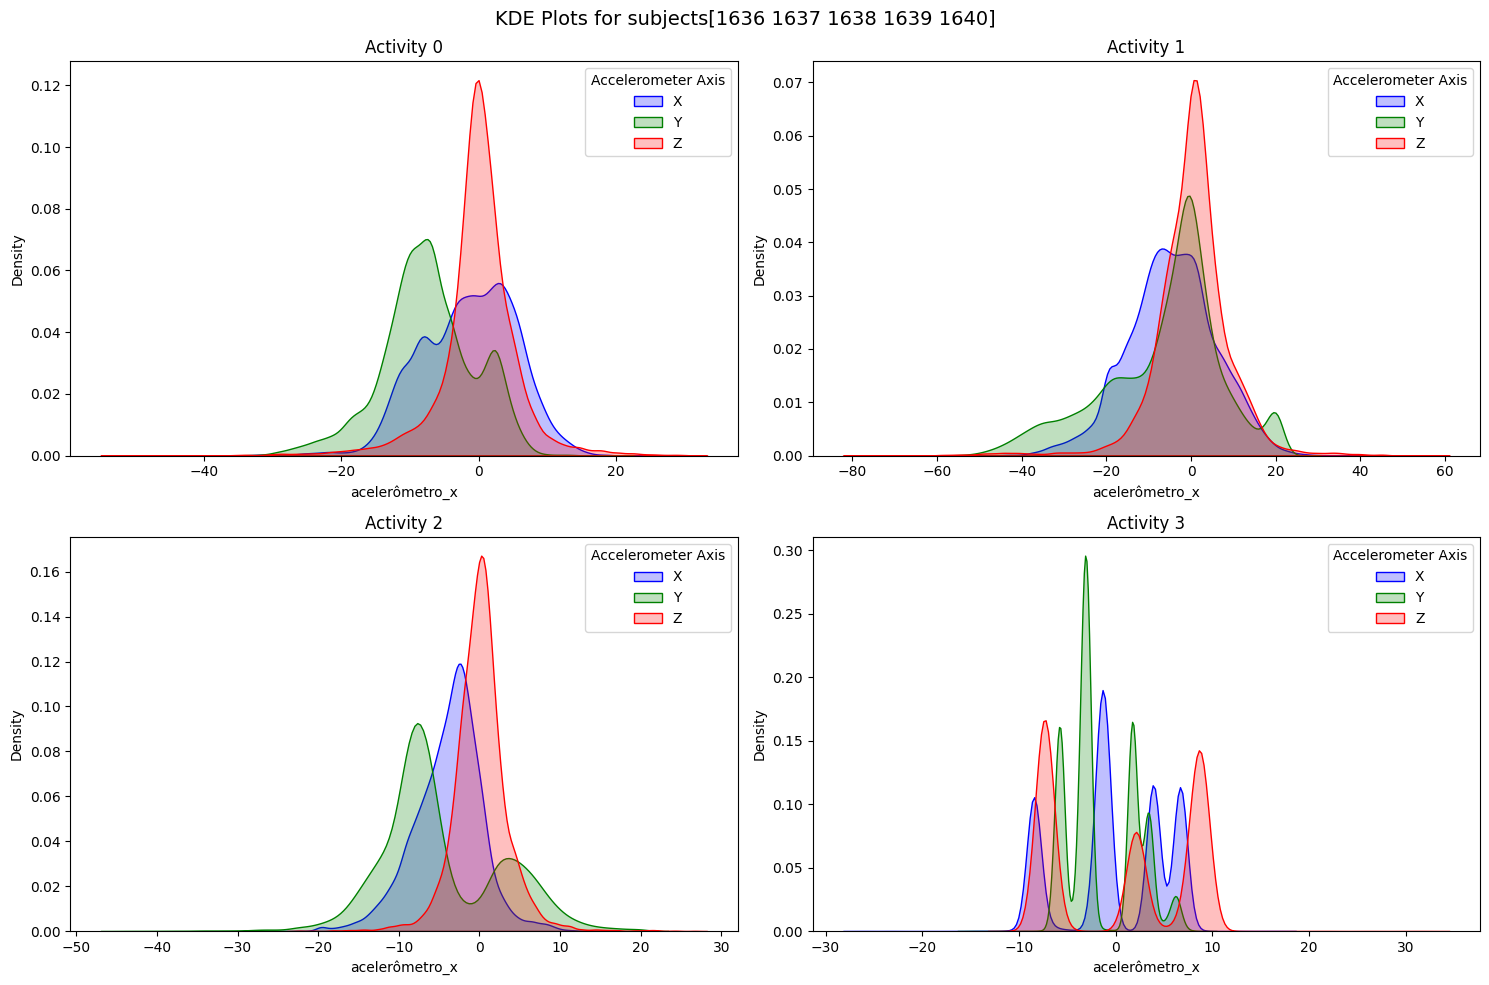

imprimindo tamanho do set 5


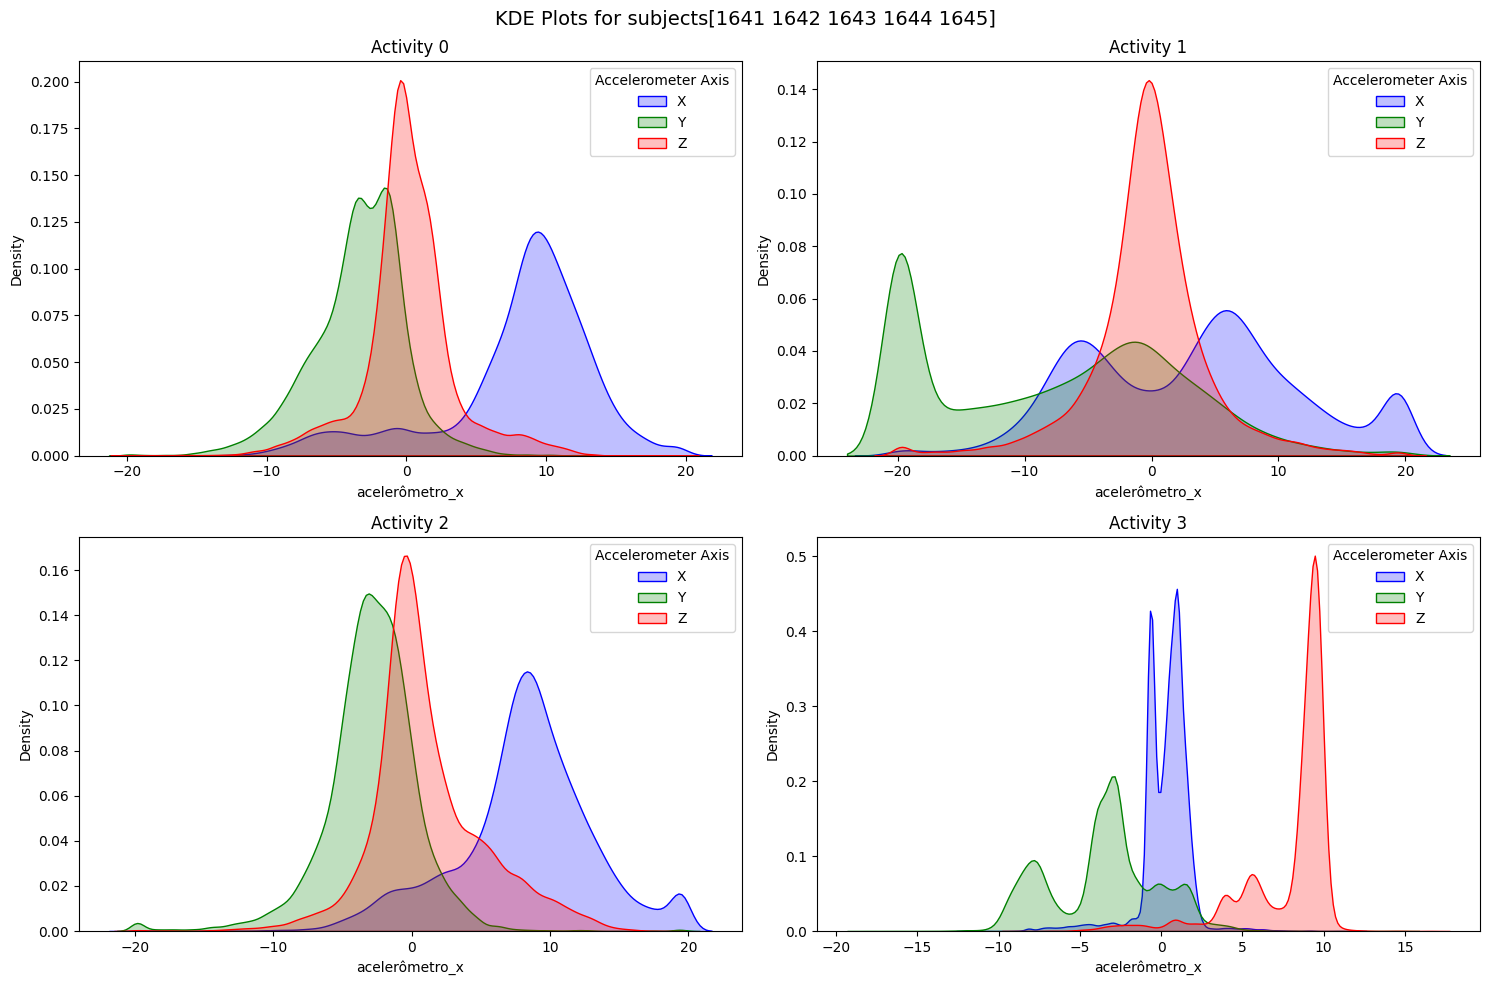

imprimindo tamanho do set 5


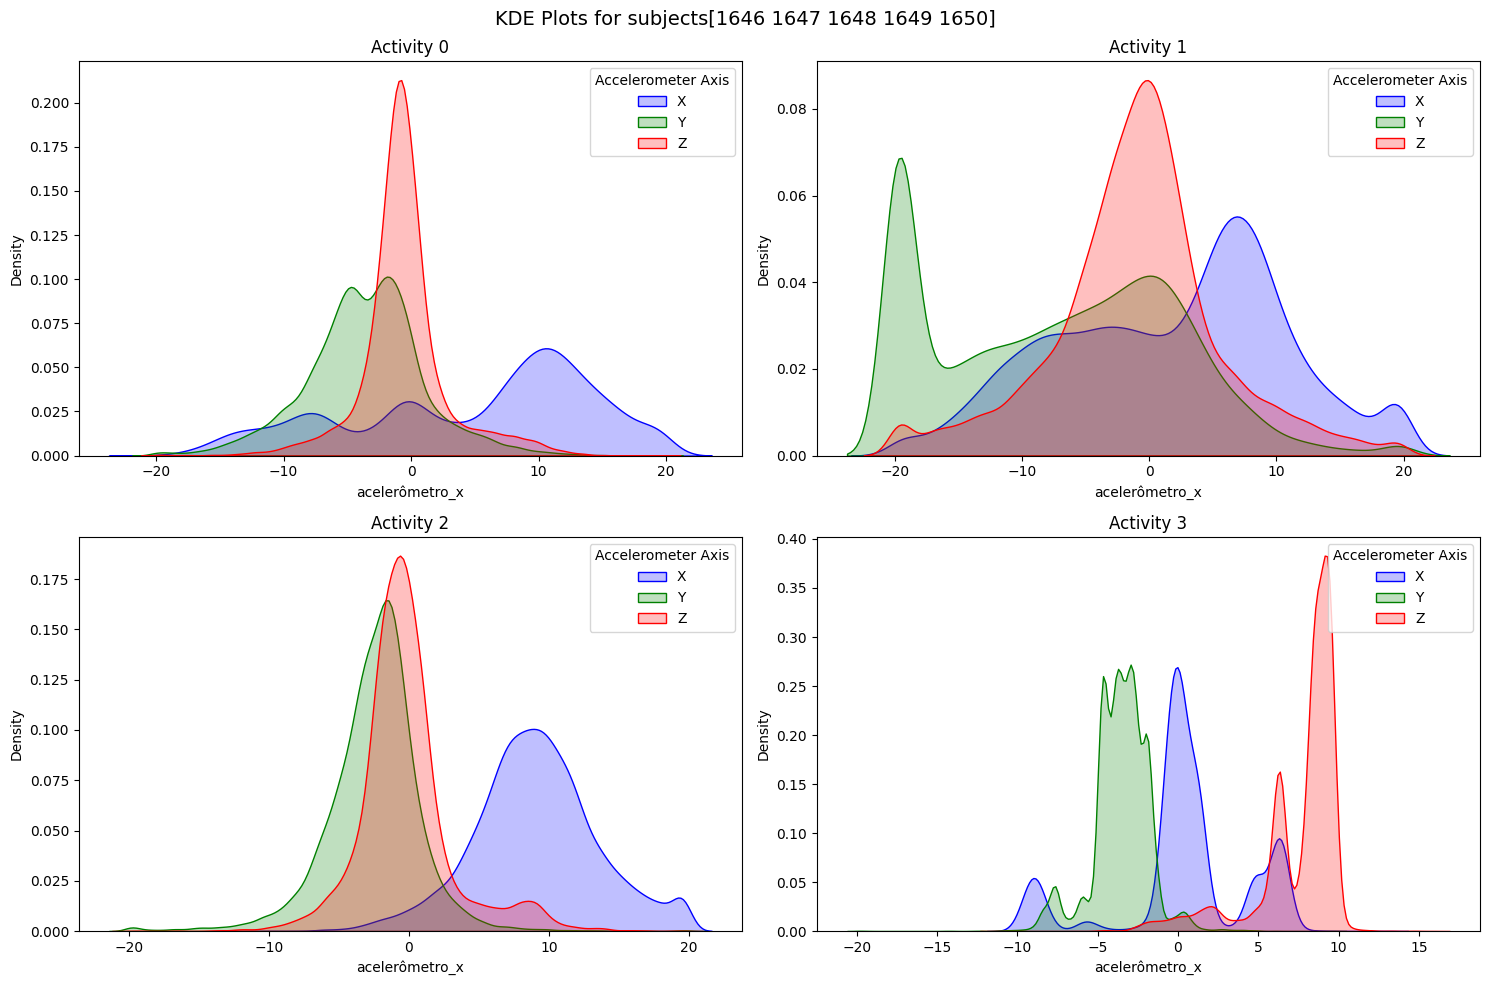

imprimindo tamanho do set 5


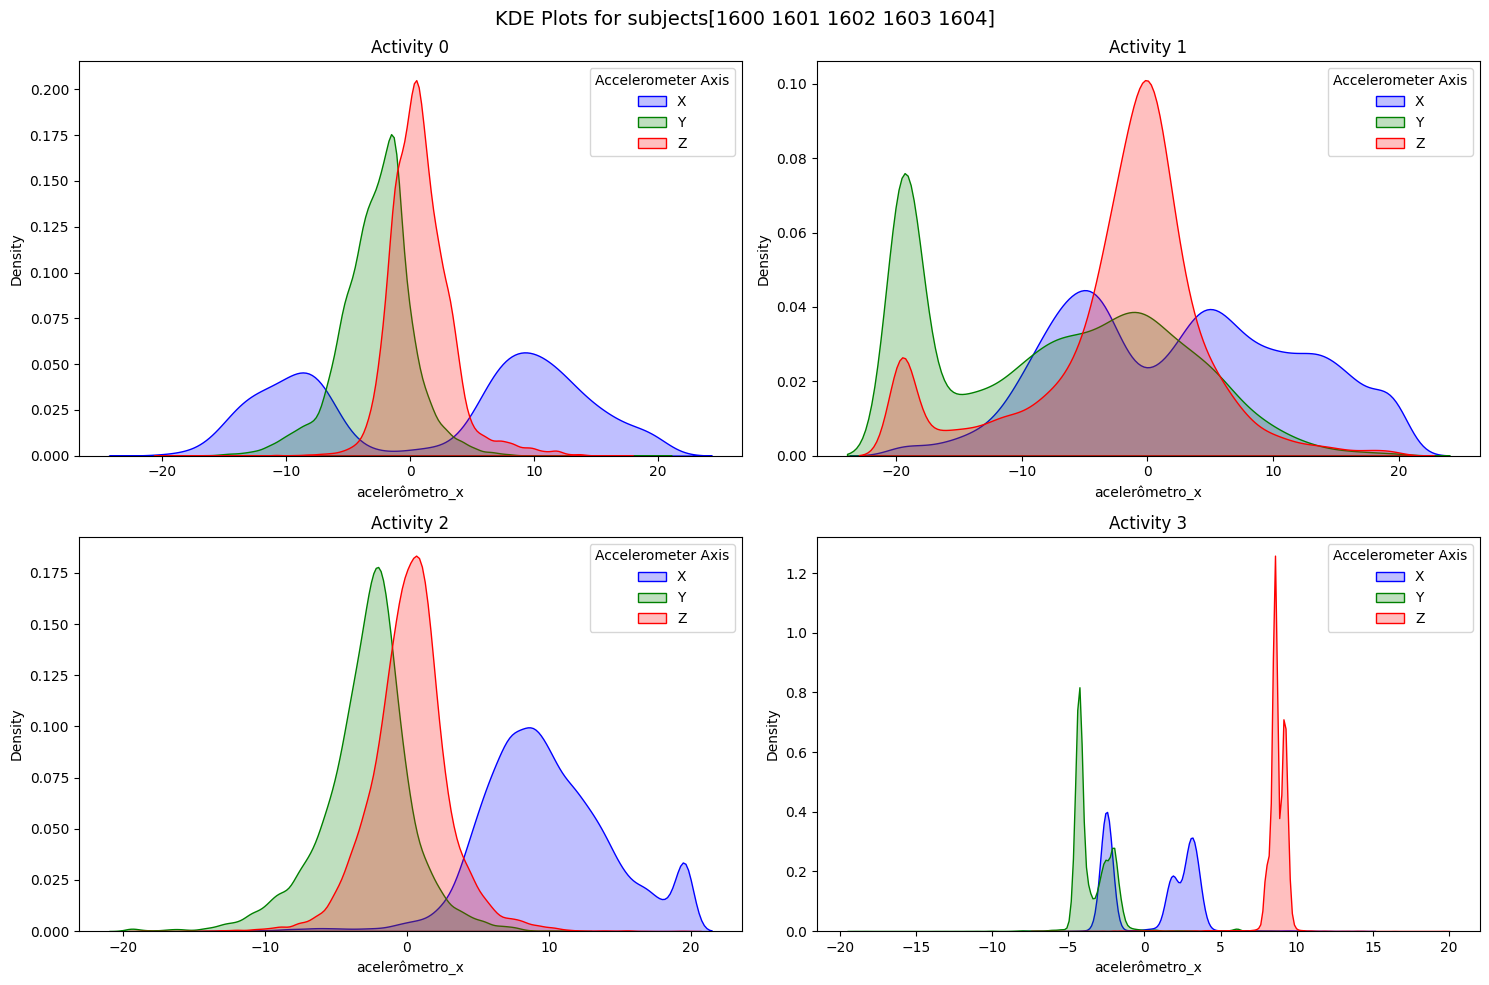

imprimindo tamanho do set 5


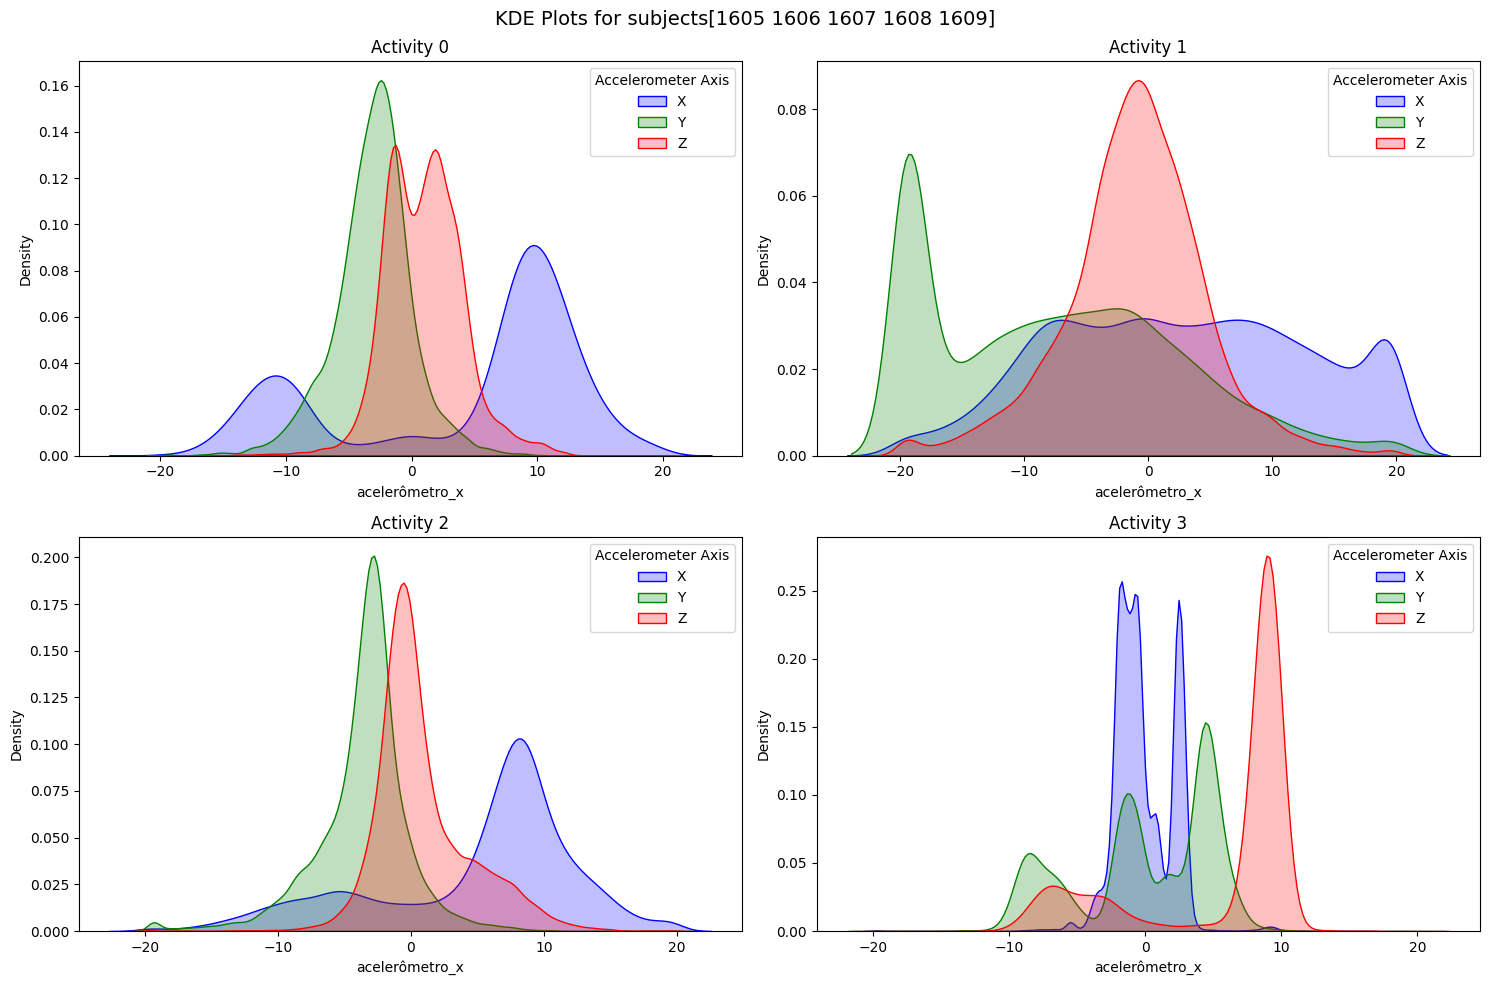

imprimindo tamanho do set 5


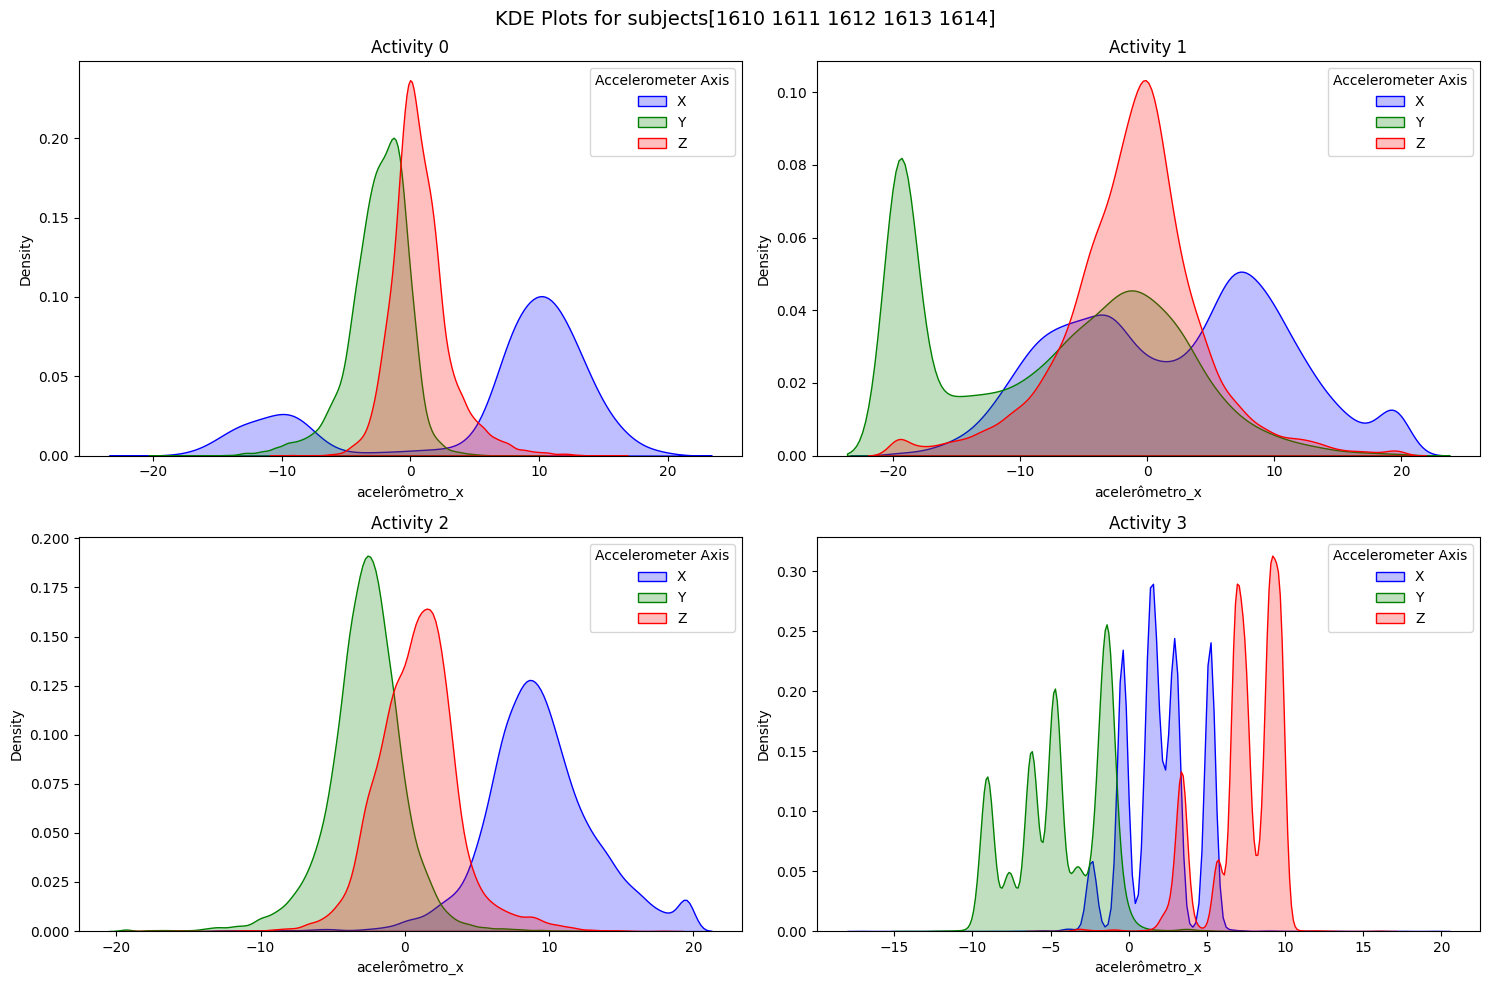

imprimindo tamanho do set 5


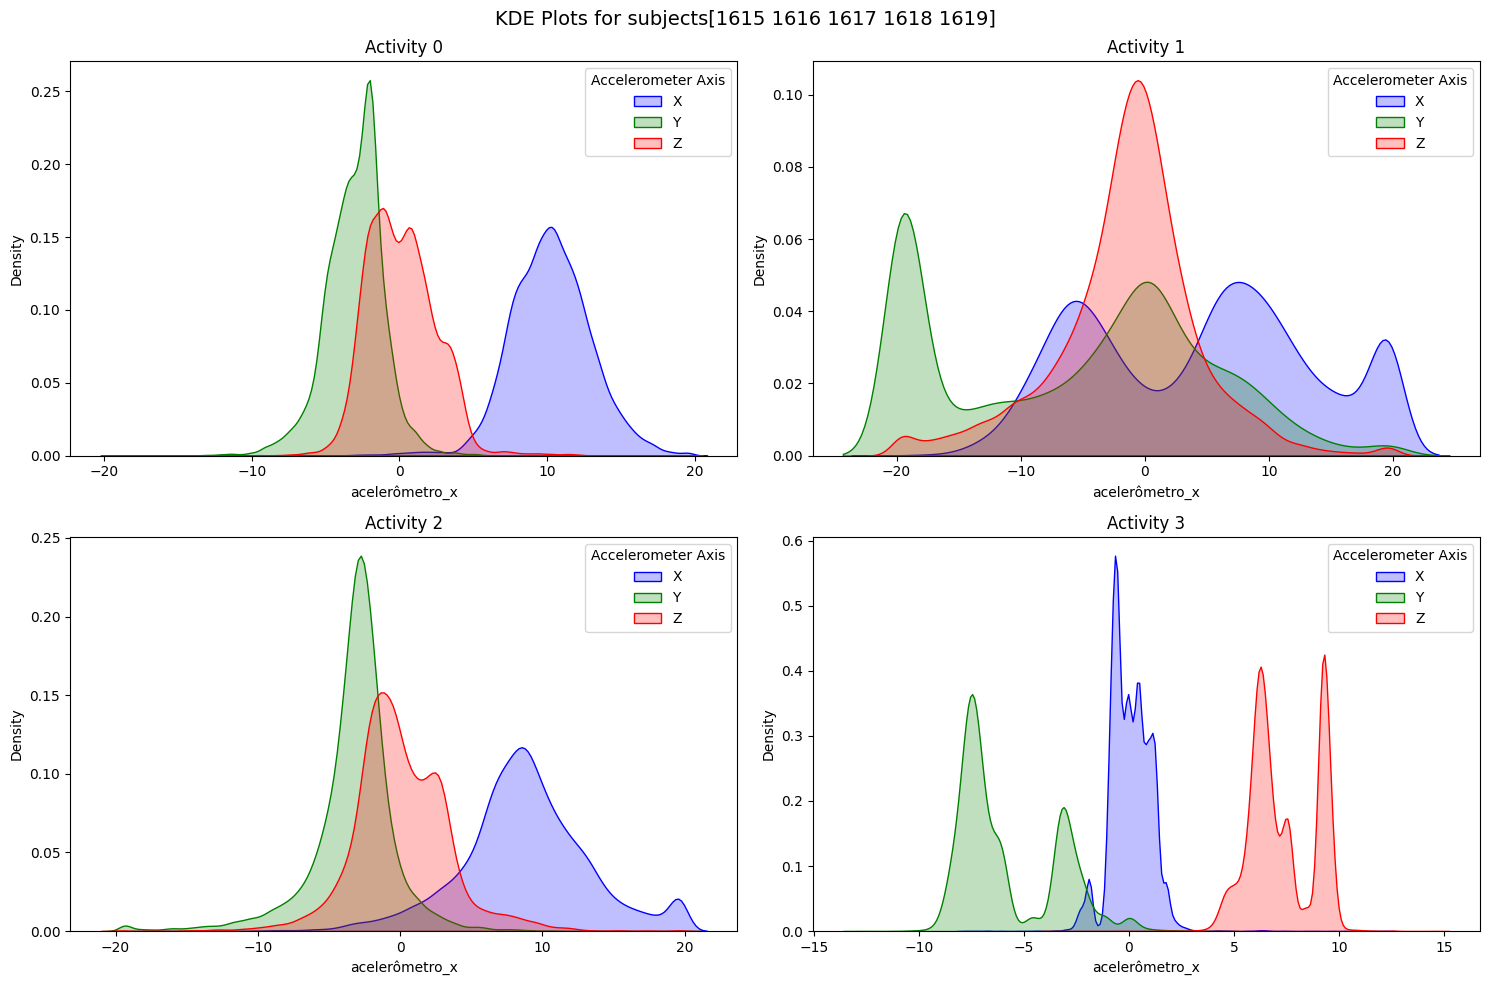

imprimindo tamanho do set 5


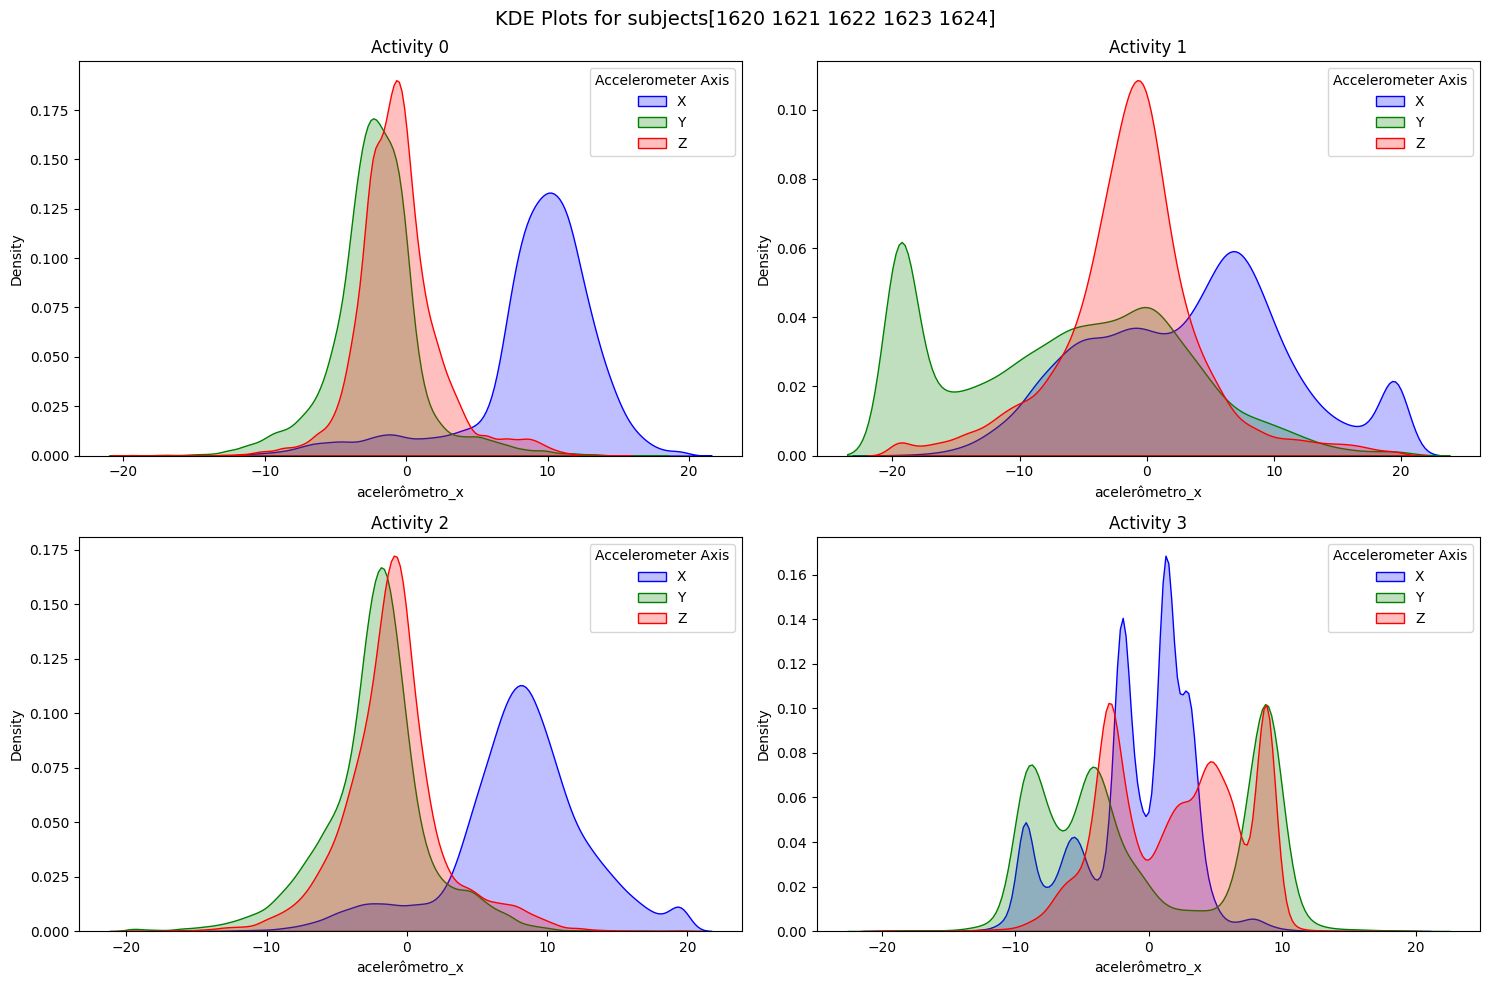

imprimindo tamanho do set 6


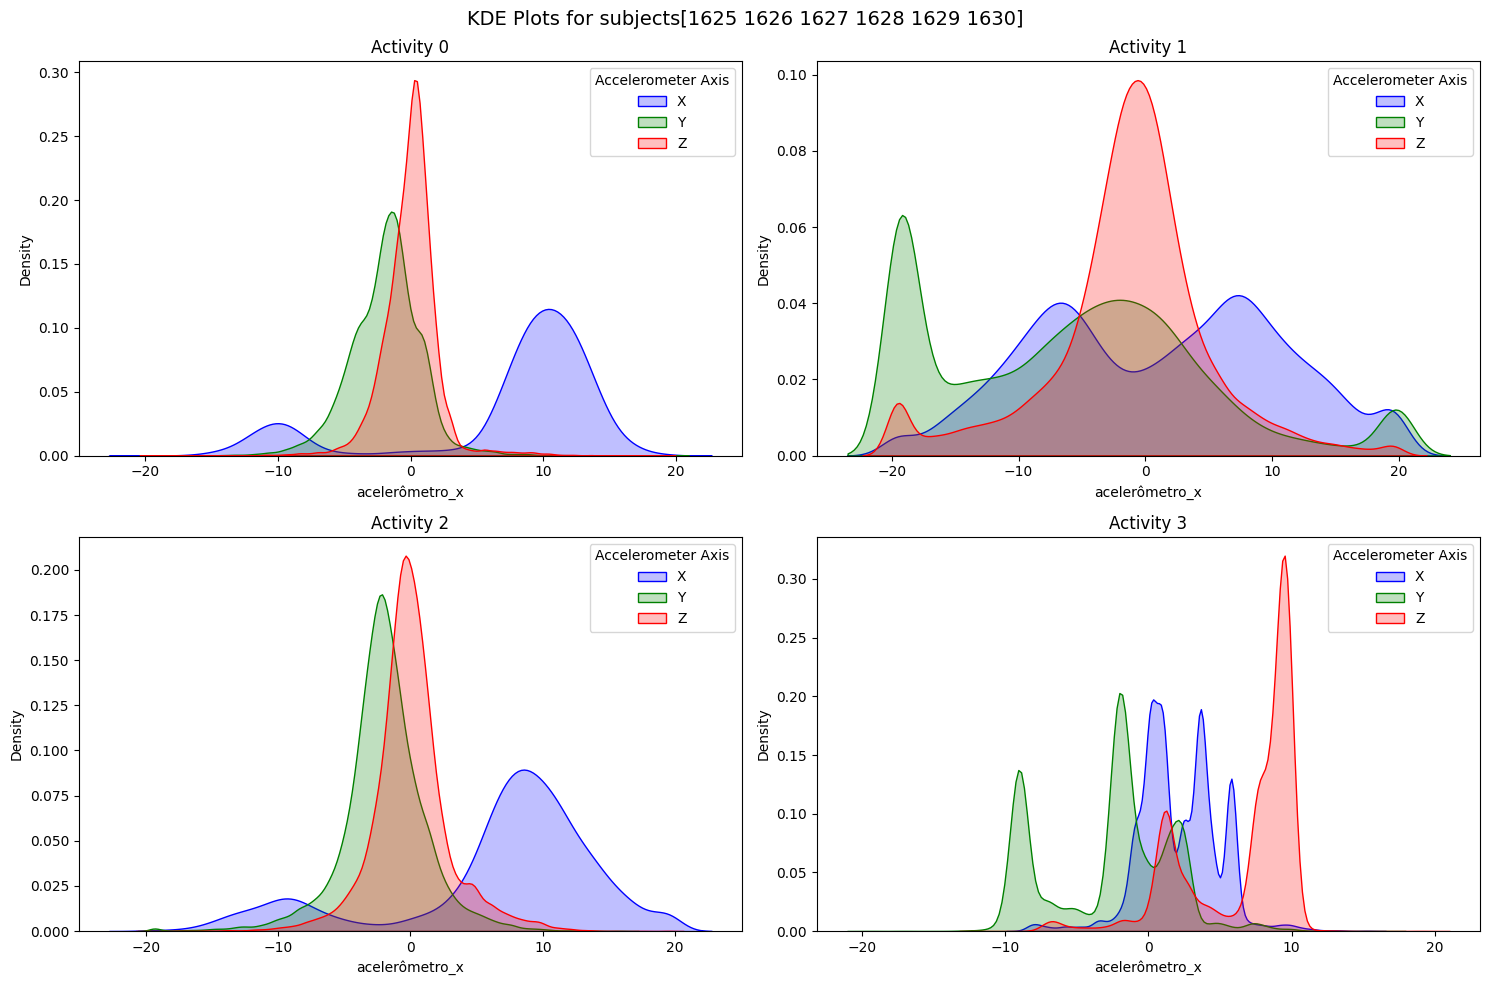

imprimindo tamanho do set 5


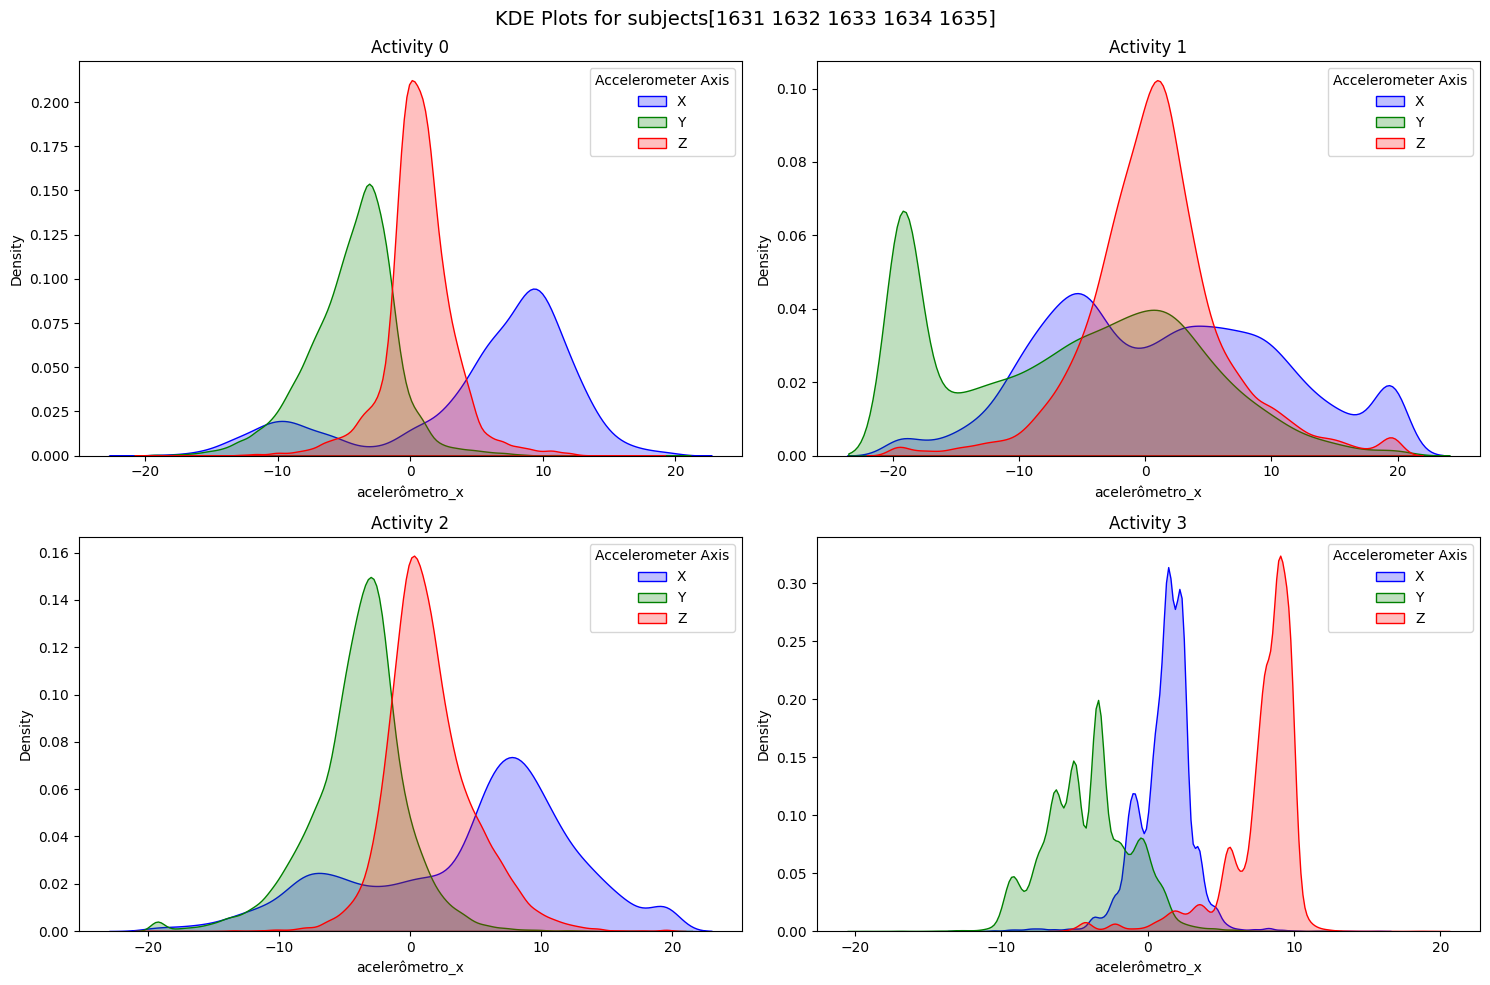

In [69]:
activities = data['atividade'].unique()
for set in combined_validation_sets:    
    # Assuming your DataFrame is named 'data'
    print(f"imprimindo tamanho do set {len(set)}")
    df = data[data["pessoa_x"].isin(set)]    
    rows = 2
    cols = 2  # Calculate number of rows and columns for subplots

    # Create figure and adjust layout
    fig, axes = plt.subplots(rows, cols, figsize=(15, 10))
    fig.suptitle(f'KDE Plots for subjects{set}', fontsize=14)

    # Iterate over activities and create subplots with KDE plots
    for i, activity in enumerate(activities):
        row, col = divmod(i, cols)
        
        # Plot for 'acelerômetro_x'
        sns.kdeplot(df[df['atividade'] == activity]['acelerômetro_x'], 
                    ax=axes[row, col], color='b', shade=True, label='X')
        
        # Plot for 'acelerômetro_y' (add similar lines for other columns)
        sns.kdeplot(df[df['atividade'] == activity]['acelerômetro_Y'], 
                    ax=axes[row, col], color='g', shade=True, label='Y')
        
        # Plot for 'acelerômetro_z' (add similar lines for other columns)
        sns.kdeplot(df[df['atividade'] == activity]['acelerômetro_Z'], 
                    ax=axes[row, col], color='r', shade=True, label='Z')
        
        # Set title and legend for each subplot
        axes[row, col].set_title(f'Activity {activity}')
        axes[row, col].legend(title='Accelerometer Axis')

    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()

In [120]:
validation_set1=np.arange(1636,1641)
validation_set2=np.arange(1641,1646)
validation_set3=np.arange(1646,1651)
validation_set4=np.arange(1600,1605)
validation_set5=np.arange(1605,1610)
validation_set6=np.arange(1610,1615)
validation_set7=np.arange(1615,1620)
validation_set8=np.arange(1620,1625)
validation_set9=np.arange(1625,1631)
validation_set10=np.arange(1631,1636)
combined_validation_sets_giro = [validation_set1, validation_set2, validation_set3, validation_set4,
validation_set5,validation_set6,validation_set7,validation_set8,validation_set9,validation_set10]

imprimindo tamanho do set 5


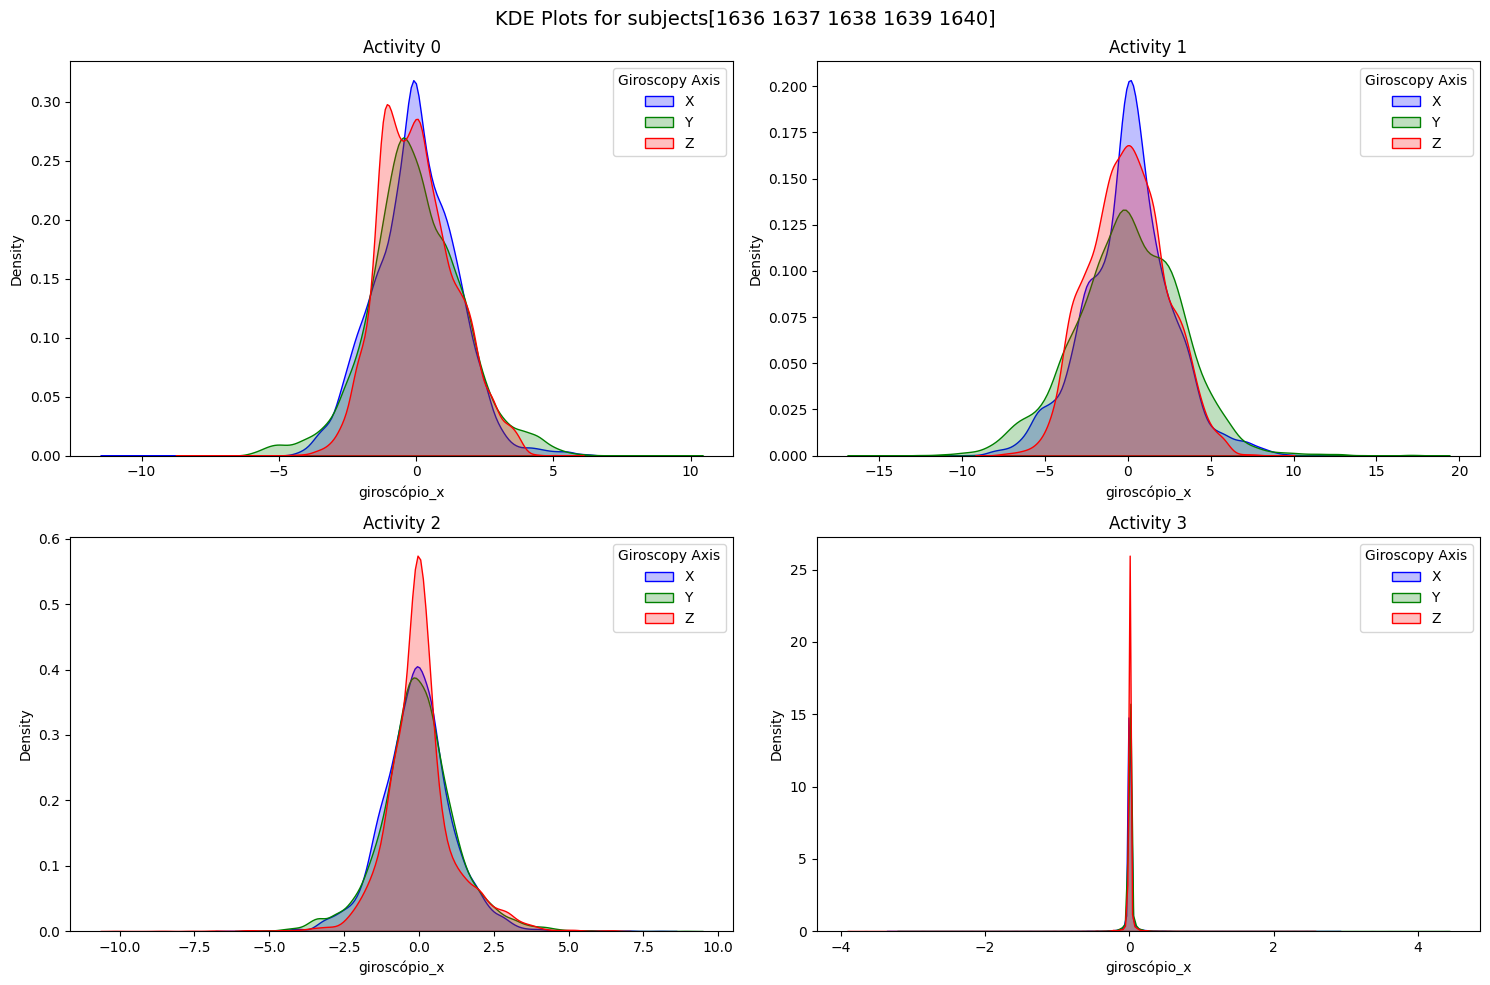

imprimindo tamanho do set 5


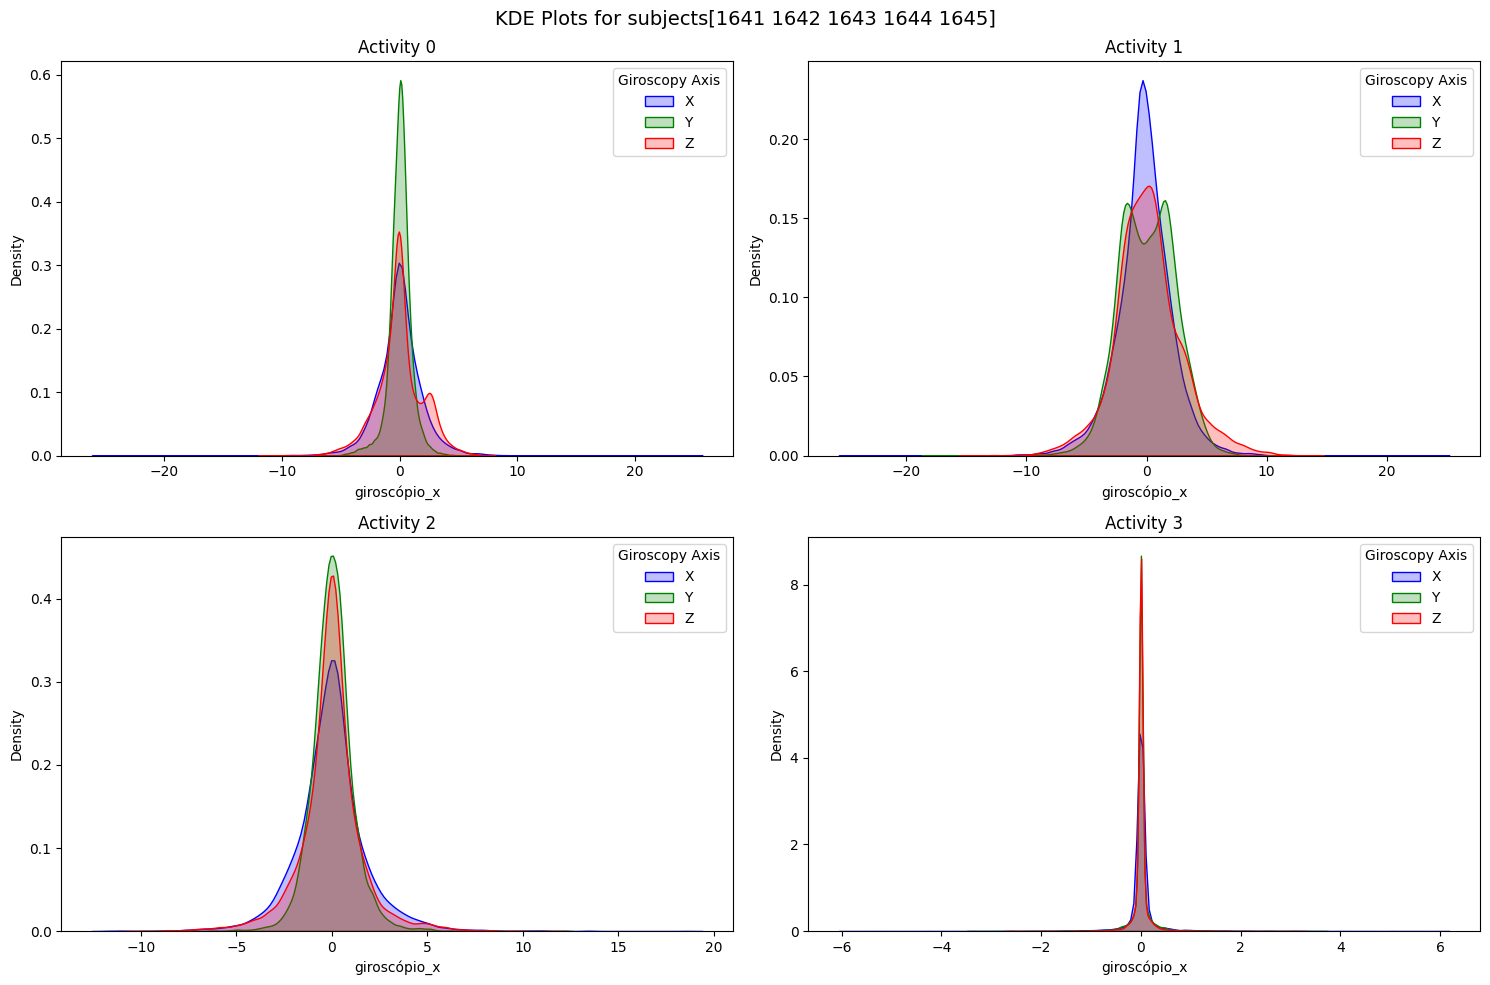

imprimindo tamanho do set 5


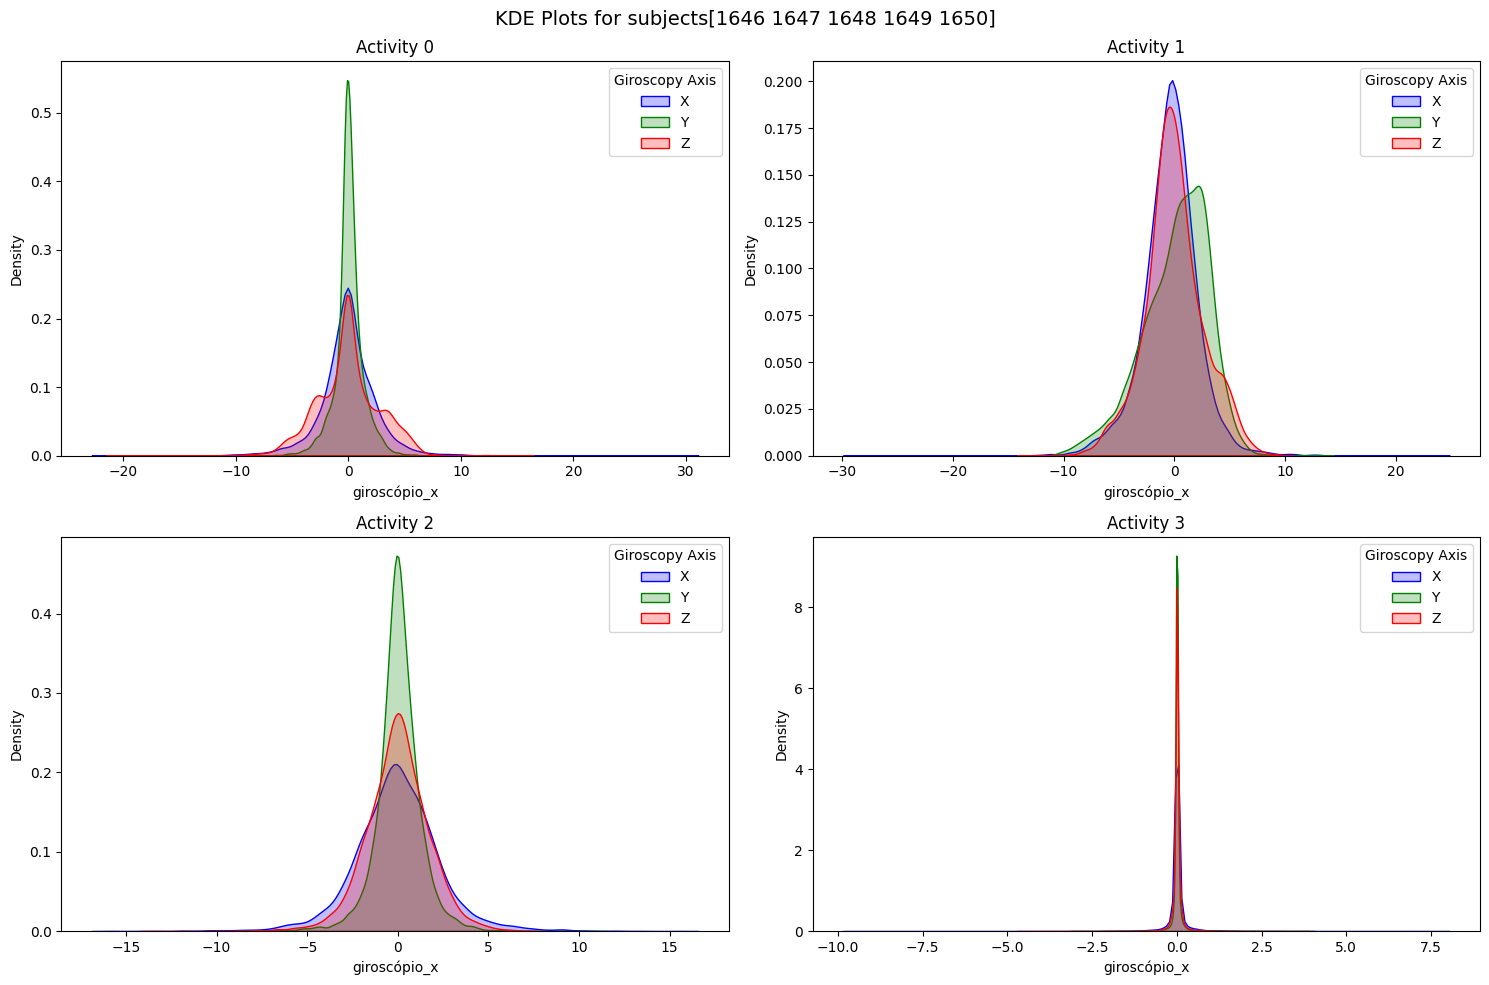

imprimindo tamanho do set 5


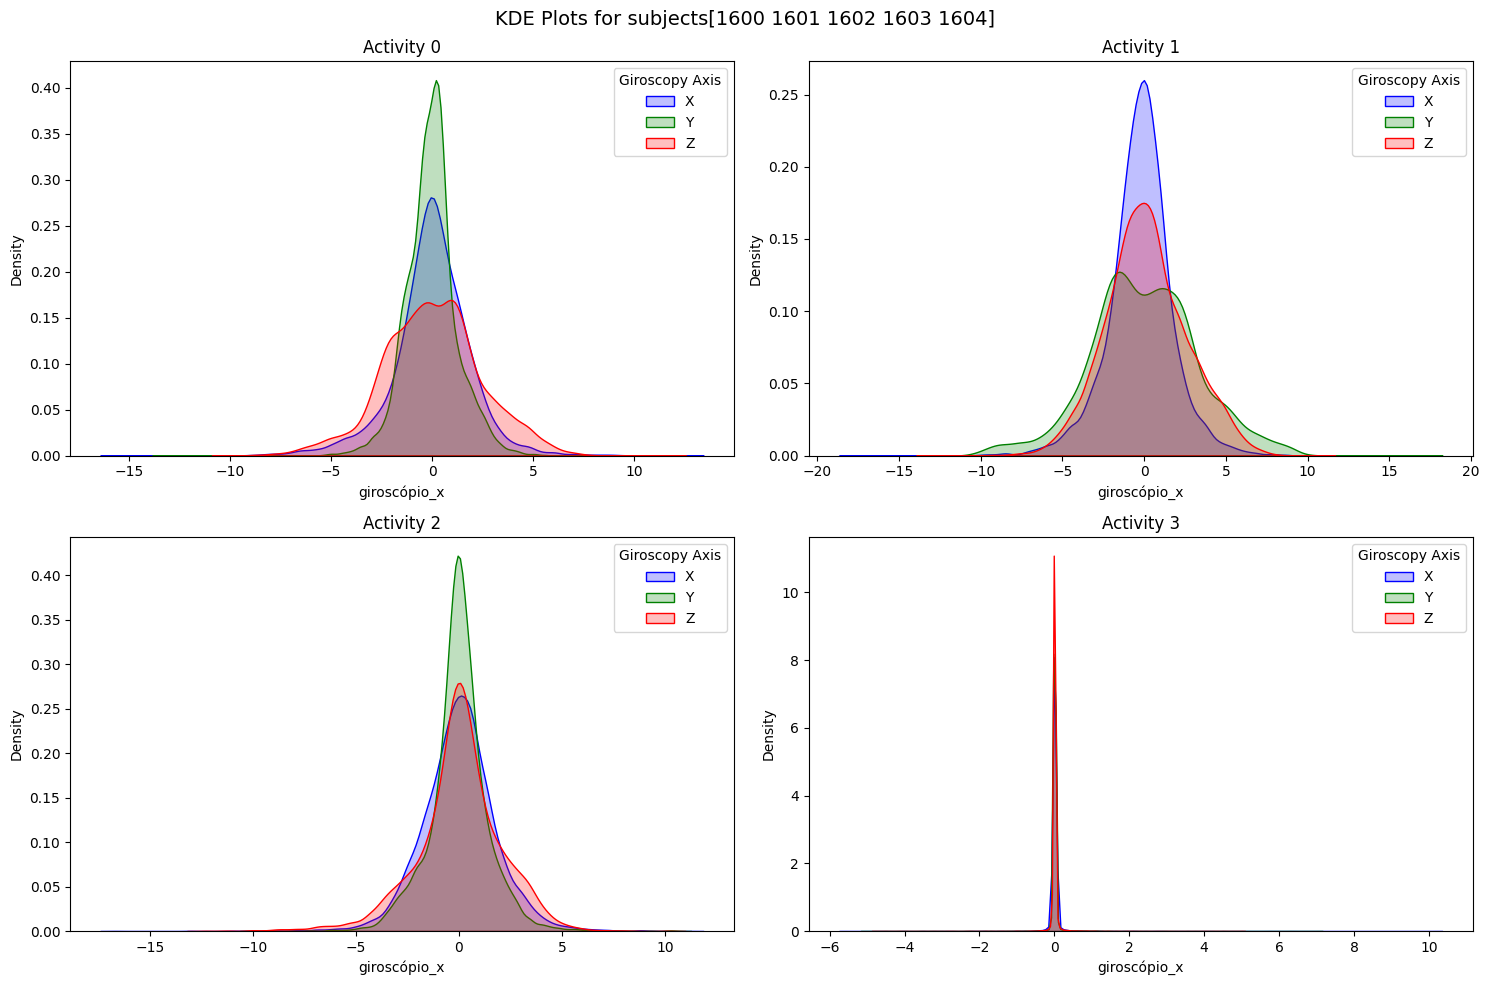

imprimindo tamanho do set 5


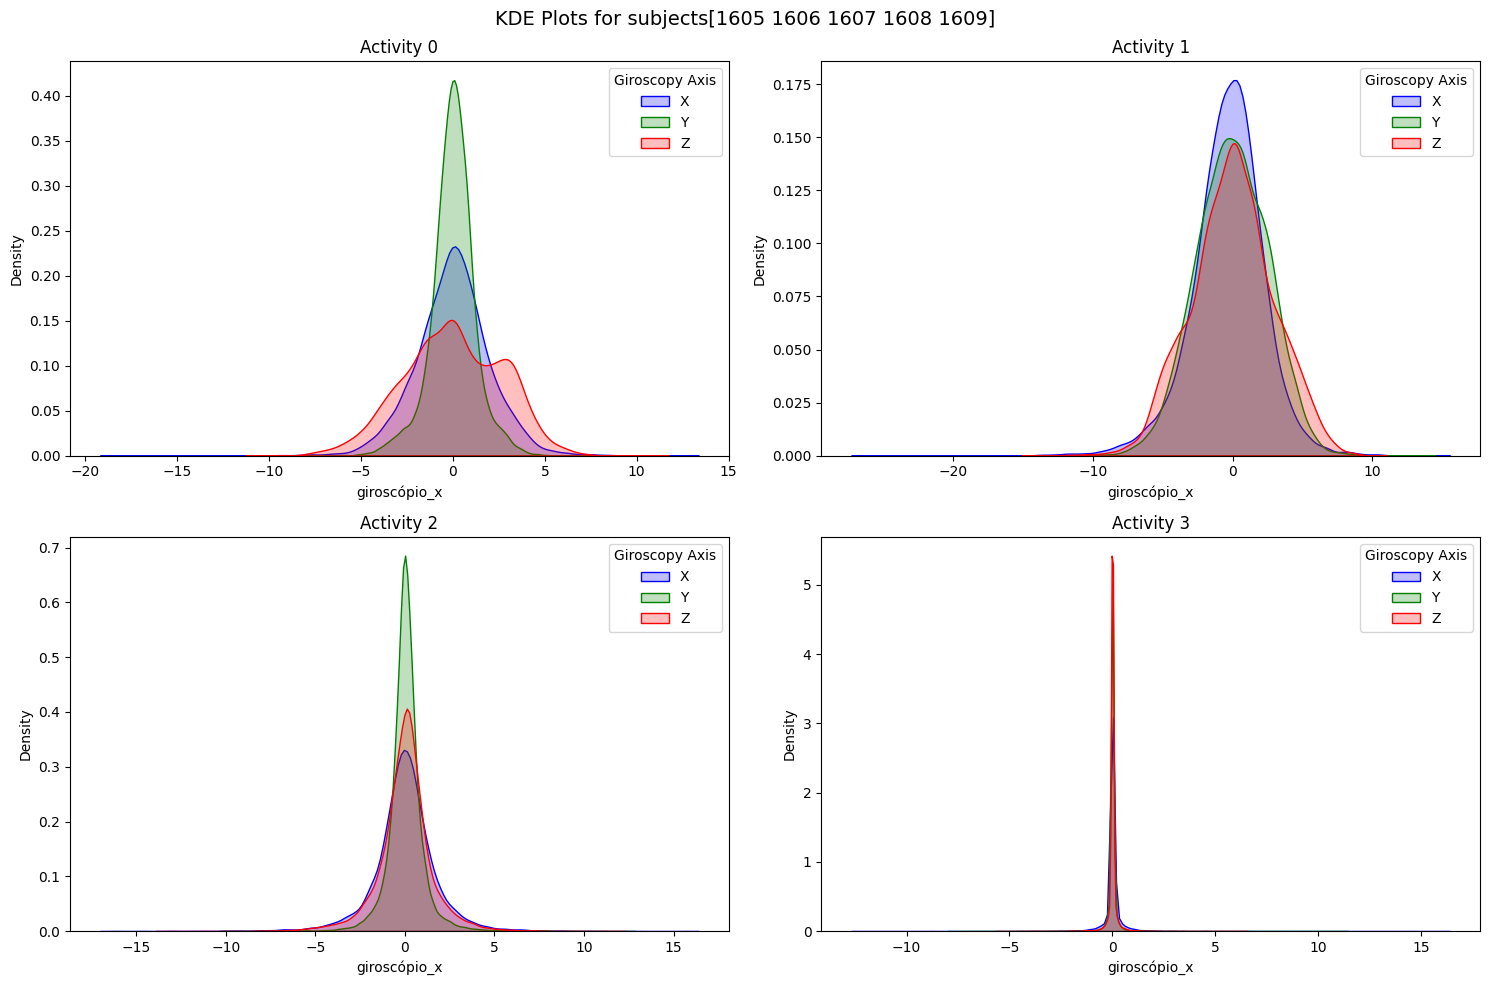

imprimindo tamanho do set 5


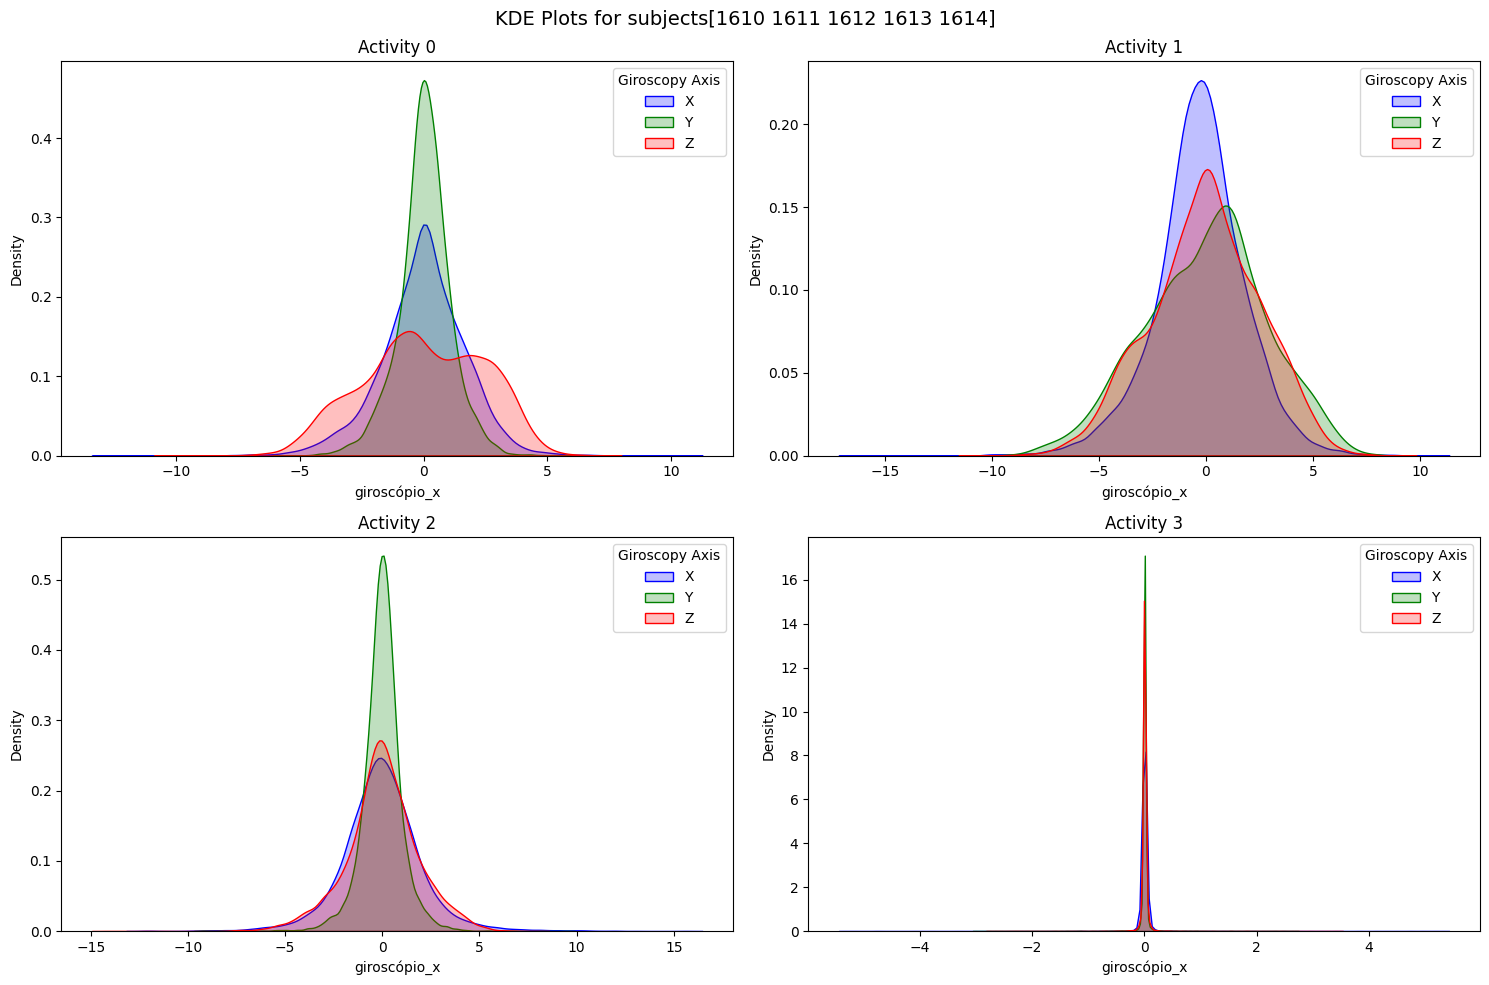

imprimindo tamanho do set 5


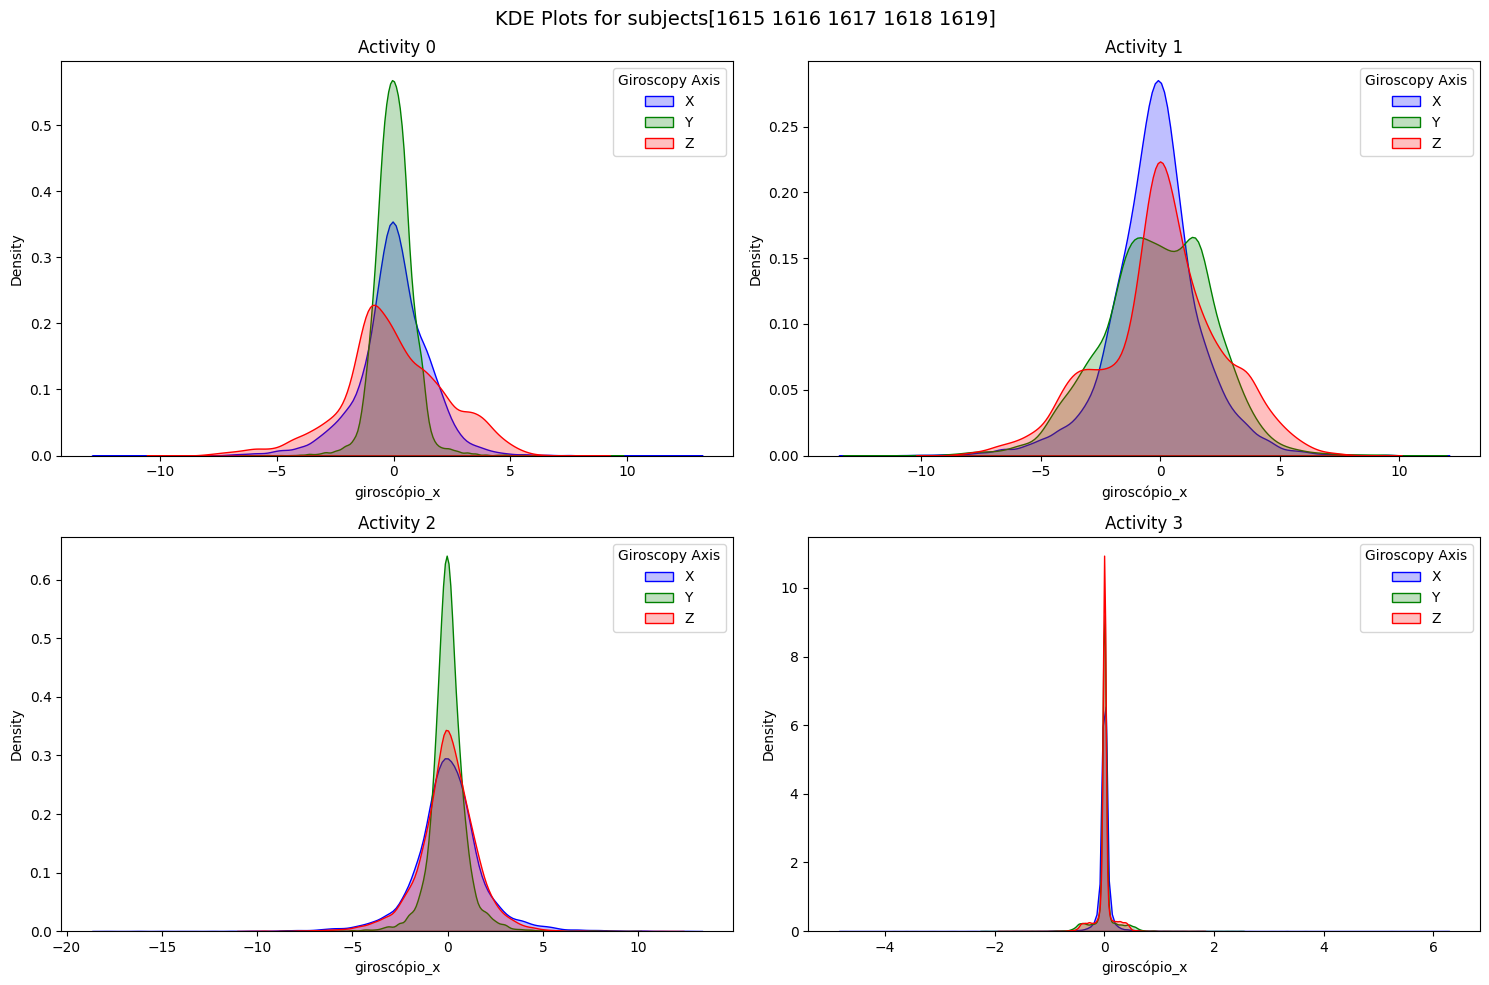

imprimindo tamanho do set 5


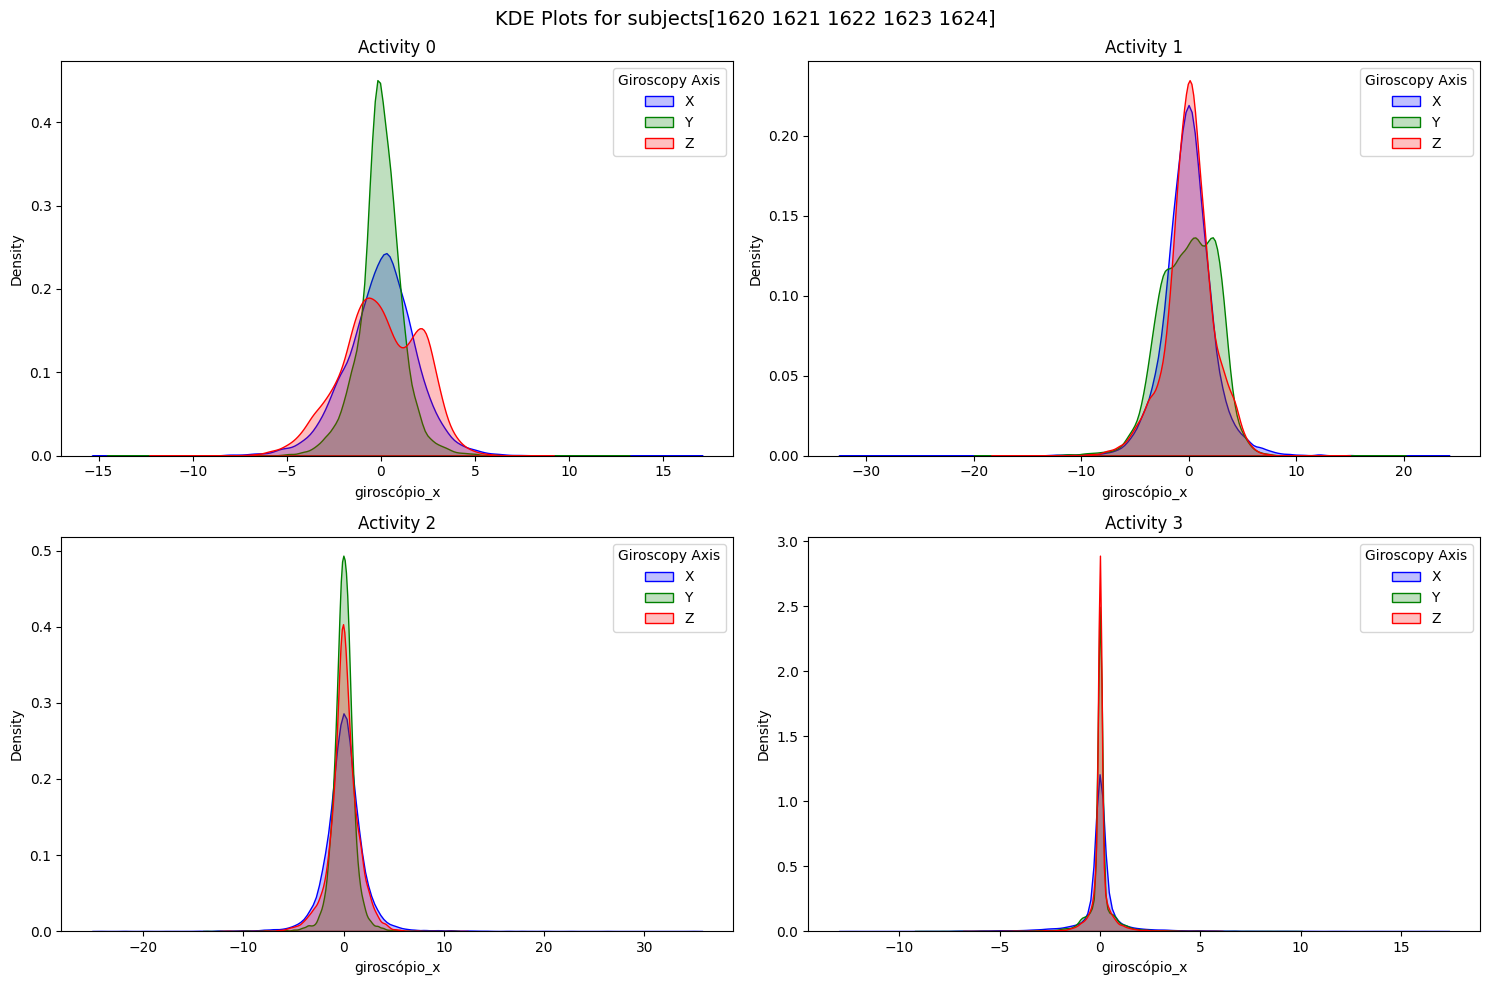

imprimindo tamanho do set 6


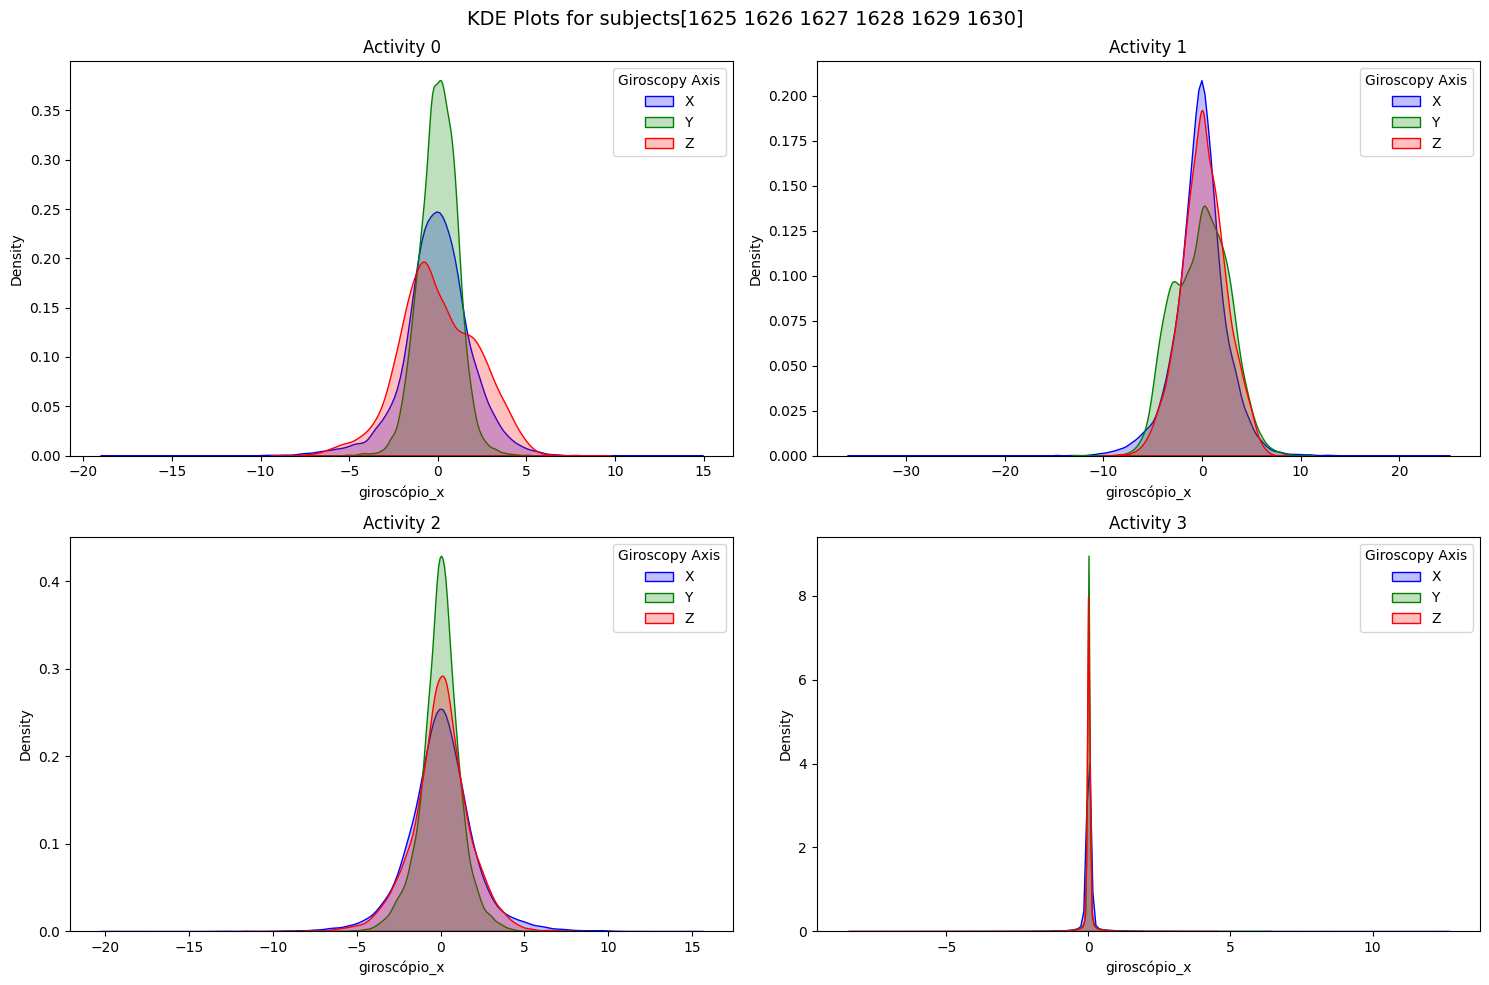

imprimindo tamanho do set 5


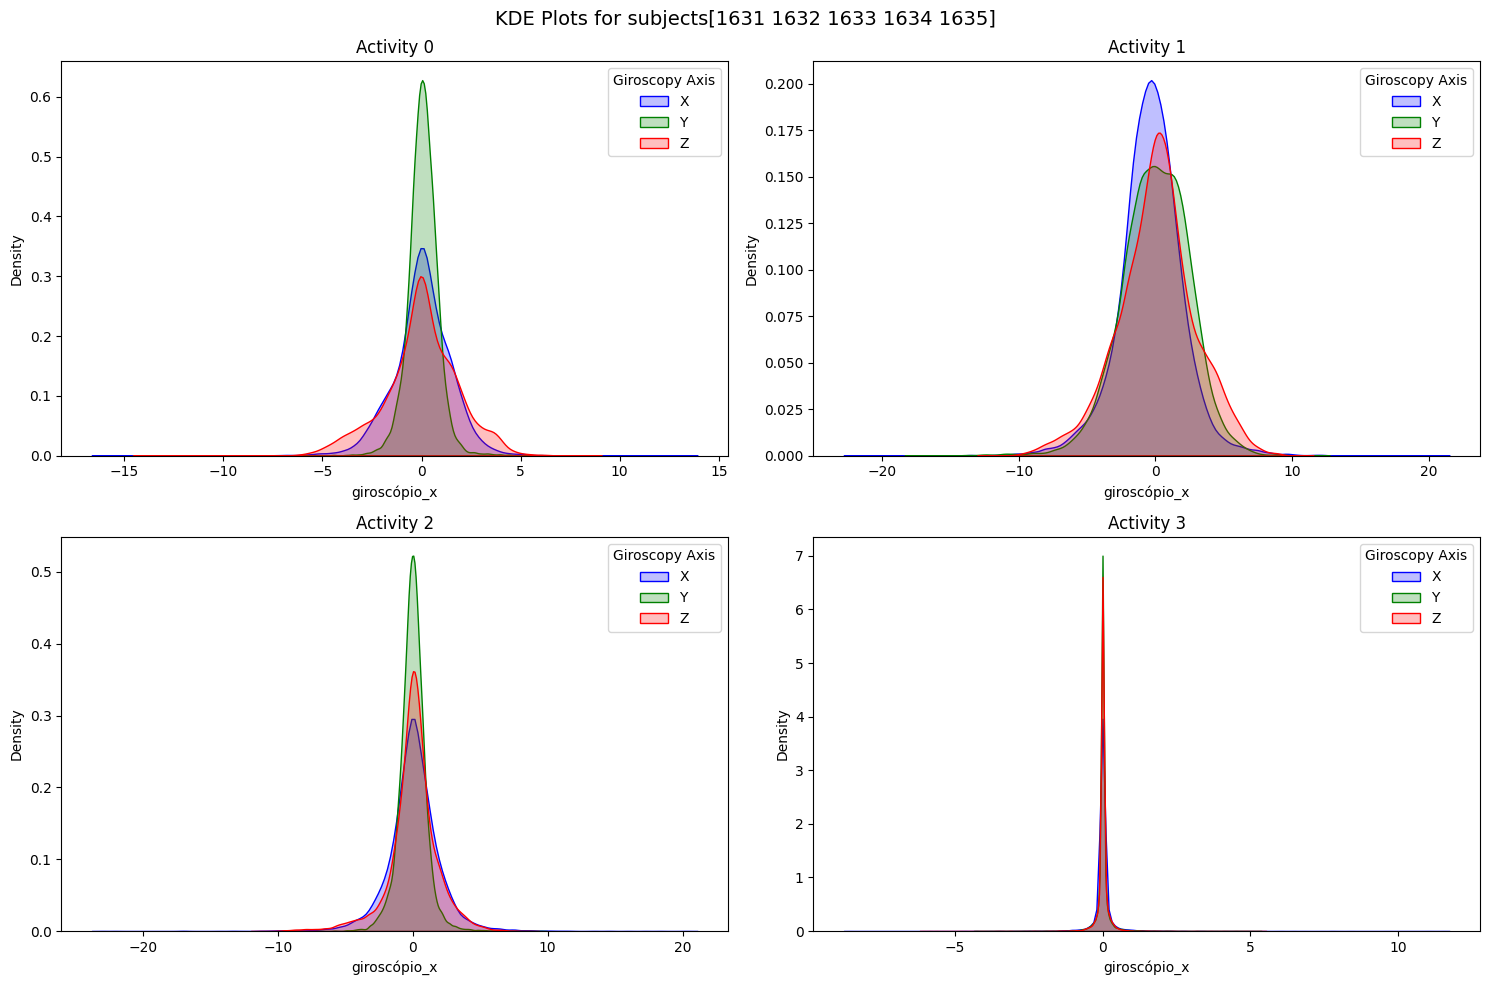

In [121]:
activities = data['atividade'].unique()
for set in combined_validation_sets_giro:    
    # Assuming your DataFrame is named 'data'
    print(f"imprimindo tamanho do set {len(set)}")
    df = data[data["pessoa_x"].isin(set)]    
    rows = 2
    cols = 2  # Calculate number of rows and columns for subplots

    # Create figure and adjust layout
    fig, axes = plt.subplots(rows, cols, figsize=(15, 10))
    fig.suptitle(f'KDE Plots for subjects{set}', fontsize=14)

    # Iterate over activities and create subplots with KDE plots
    for i, activity in enumerate(activities):
        row, col = divmod(i, cols)
        
        # Plot for 'giroscópio_x'
        sns.kdeplot(df[df['atividade'] == activity]['giroscópio_x'], 
                    ax=axes[row, col], color='b', shade=True, label='X')
        
        # Plot for 'giroscópio_y' (add similar lines for other columns)
        sns.kdeplot(df[df['atividade'] == activity]['giroscópio_Y'], 
                    ax=axes[row, col], color='g', shade=True, label='Y')
        
        # Plot for 'giroscópio_z' (add similar lines for other columns)
        sns.kdeplot(df[df['atividade'] == activity]['giroscópio_Z'], 
                    ax=axes[row, col], color='r', shade=True, label='Z')
        
        # Set title and legend for each subplot
        axes[row, col].set_title(f'Activity {activity}')
        axes[row, col].legend(title='Giroscopy Axis')

    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()

In [70]:
#remove the null class
data=data.dropna()

# **Data Exploration**

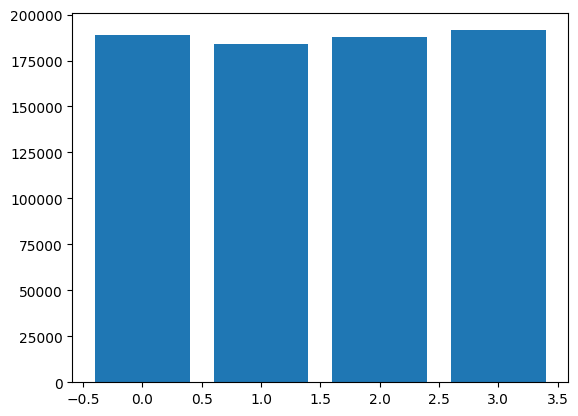

In [71]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

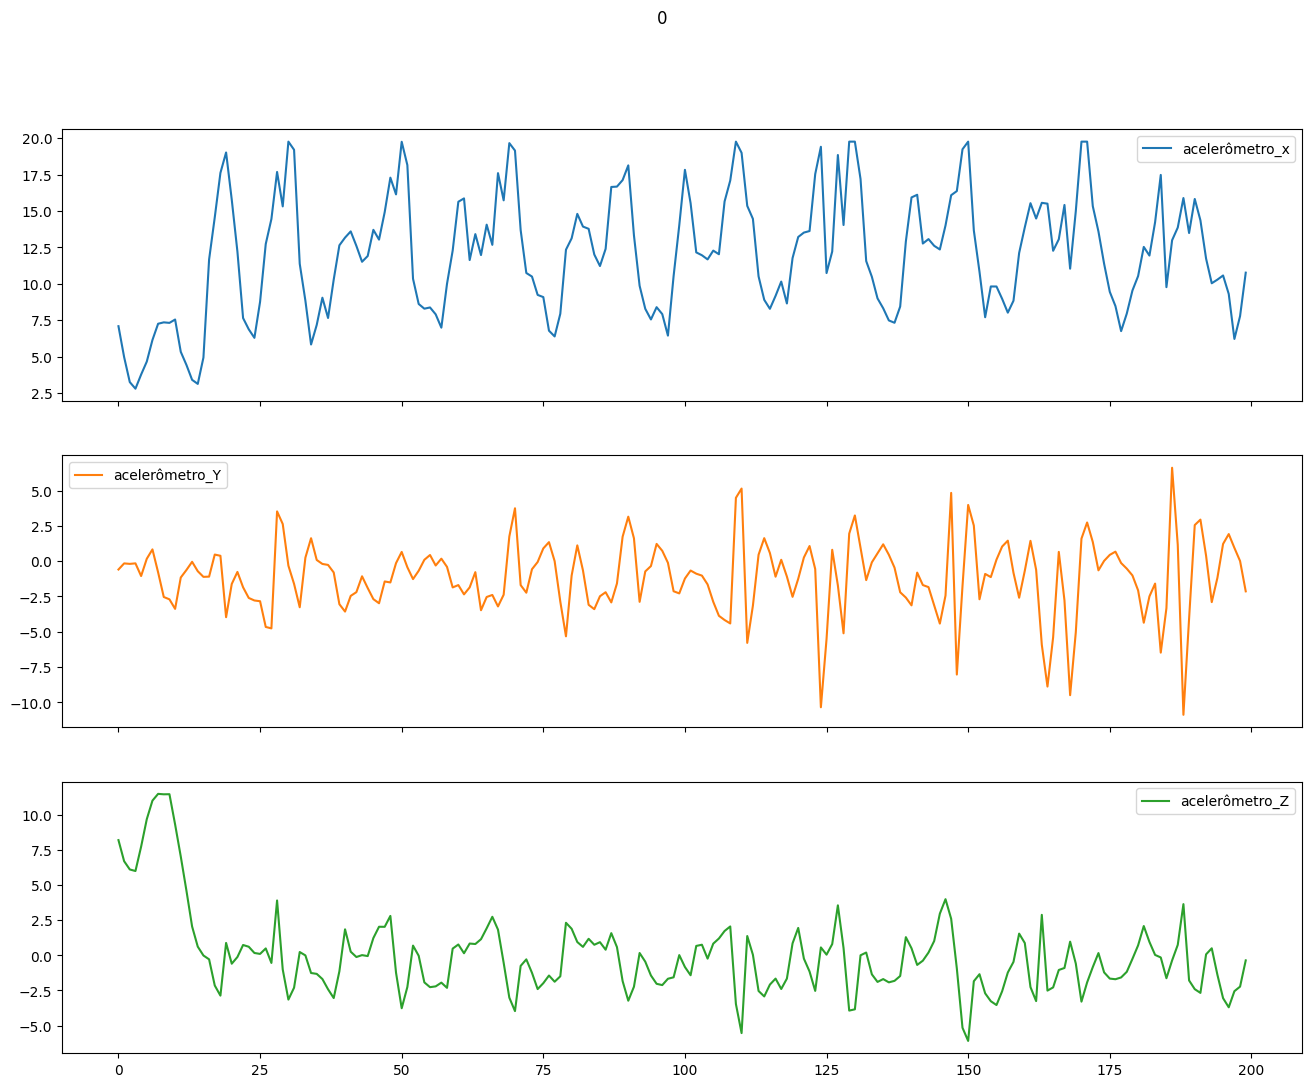

In [72]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

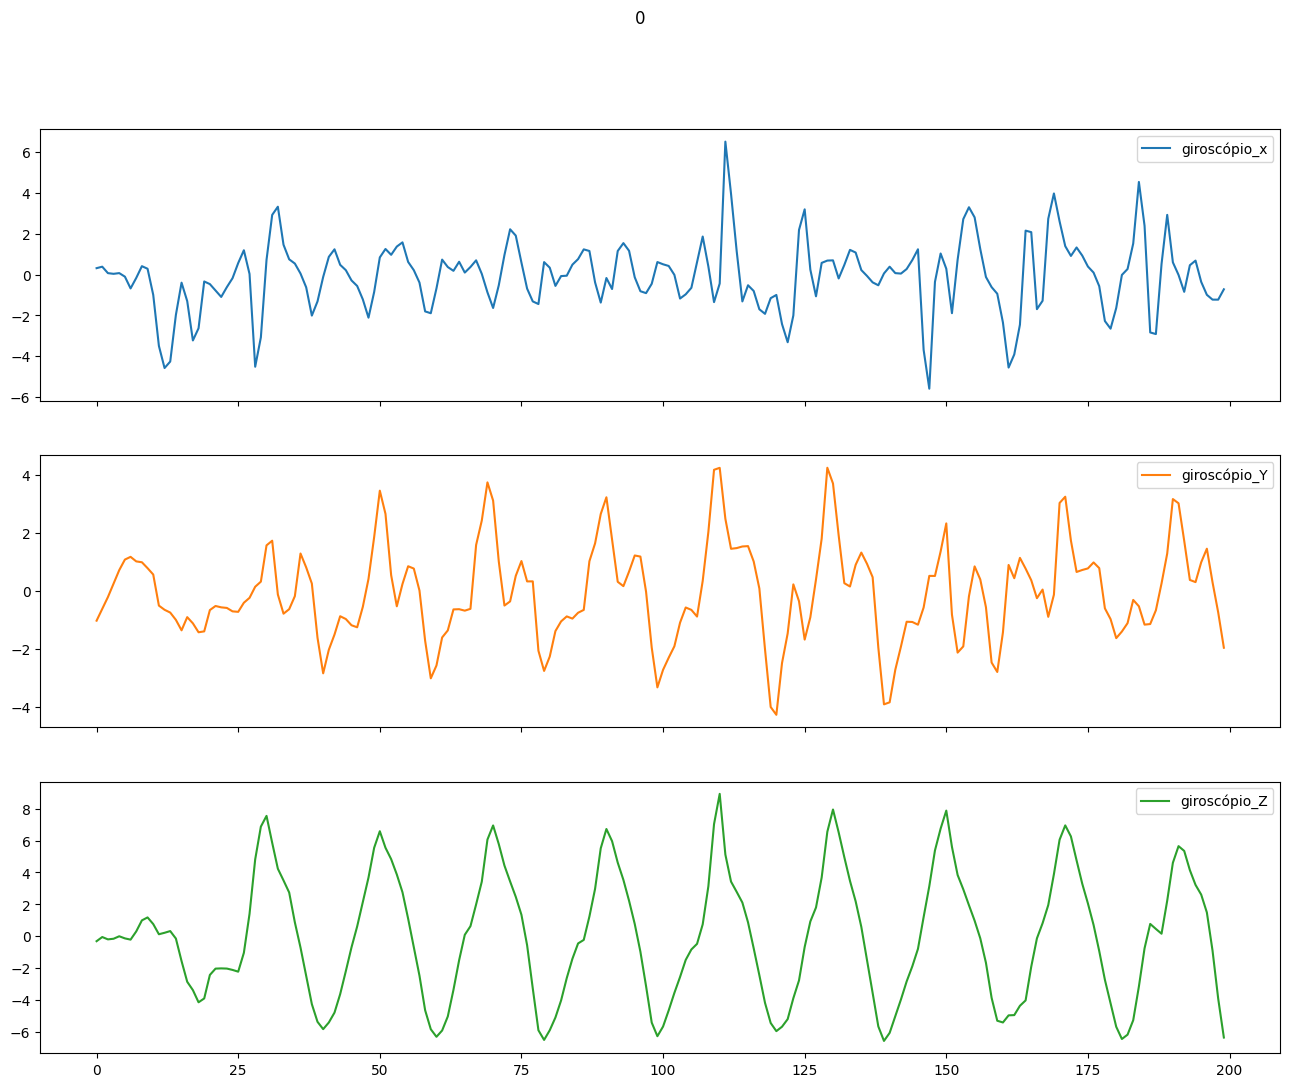

In [73]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [74]:
data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().sort_index()

(Index([1629, 1621, 1601, 1638, 1639, 1645, 1650, 1647, 1625, 1624, 1614, 1630,
        1626, 1600, 1632, 1631, 1627, 1604, 1634, 1622, 1611, 1606, 1602, 1636,
        1635, 1633, 1615, 1610, 1609, 1628, 1617, 1612, 1608, 1620, 1618, 1607,
        1649, 1641, 1613, 1619, 1648, 1623, 1646, 1644, 1643, 1637, 1640, 1616,
        1605, 1603, 1642],
       dtype='int64', name='pessoa_x'),
 pessoa_x
 1600    14415
 1601    18005
 1602    14412
 1603    10806
 1604    14413
 1605    10806
 1606    14412
 1607    14408
 1608    14412
 1609    14412
 1610    14412
 1611    14413
 1612    14412
 1613    14405
 1614    14418
 1615    14412
 1616    10809
 1617    14412
 1618    14411
 1619    14400
 1620    14412
 1621    18718
 1622    14413
 1623    14397
 1624    14423
 1625    14427
 1626    14415
 1627    14414
 1628    14412
 1629    28826
 1630    14415
 1631    14414
 1632    14414
 1633    14412
 1634    14413
 1635    14412
 1636    14412
 1637    13391
 1638    17856
 1639    17842
 16

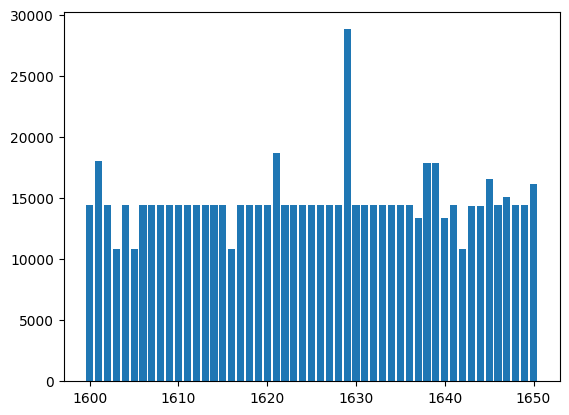

In [75]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [76]:
data.shape

(752213, 10)

In [77]:
data = data[data["pessoa_x"]!=1629]

In [78]:
data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().sort_index()

(Index([1621, 1601, 1638, 1639, 1645, 1650, 1647, 1625, 1624, 1614, 1630, 1626,
        1600, 1632, 1627, 1631, 1604, 1634, 1622, 1611, 1602, 1636, 1635, 1633,
        1612, 1609, 1628, 1608, 1610, 1606, 1620, 1615, 1617, 1618, 1607, 1649,
        1641, 1613, 1619, 1648, 1623, 1646, 1644, 1643, 1637, 1640, 1616, 1605,
        1603, 1642],
       dtype='int64', name='pessoa_x'),
 pessoa_x
 1600    14415
 1601    18005
 1602    14412
 1603    10806
 1604    14413
 1605    10806
 1606    14412
 1607    14408
 1608    14412
 1609    14412
 1610    14412
 1611    14413
 1612    14412
 1613    14405
 1614    14418
 1615    14412
 1616    10809
 1617    14412
 1618    14411
 1619    14400
 1620    14412
 1621    18718
 1622    14413
 1623    14397
 1624    14423
 1625    14427
 1626    14415
 1627    14414
 1628    14412
 1630    14415
 1631    14414
 1632    14414
 1633    14412
 1634    14413
 1635    14412
 1636    14412
 1637    13391
 1638    17856
 1639    17842
 1640    13389
 1641    

In [79]:
data.shape

(723387, 10)

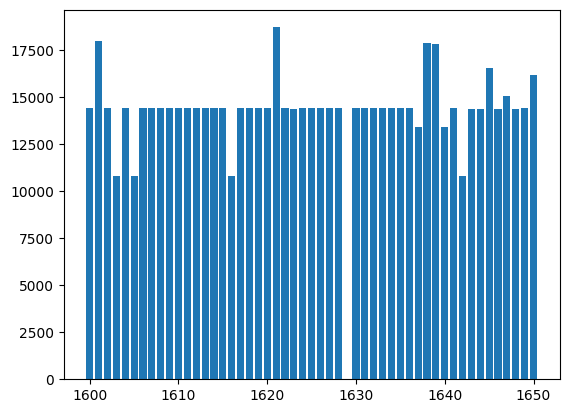

In [80]:
plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [81]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [82]:
data['root_sum_square_acel_xyz'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [83]:
data['root_sum_square_acel_xy'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Y']].pow(2).sum(axis=1))

In [84]:
data['root_sum_square_acel_xz'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [85]:
data['root_sum_square_acel_yz'] = np.sqrt(data[['acelerômetro_Y', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [86]:
data['mean_acel'] = np.mean(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [87]:
data['standard_acel'] = np.std(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [88]:
data['min_acel'] = np.min(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [89]:
data['max_acel'] = np.max(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [90]:
data['root_sum_square_giro'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']].pow(2).sum(axis=1))

In [91]:
data['root_sum_square_giro_xy'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Y']].pow(2).sum(axis=1))

In [92]:
data['root_sum_square_giro_xz'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Z']].pow(2).sum(axis=1))

In [93]:
data['root_sum_square_giro_yz'] = np.sqrt(data[['giroscópio_Y', 'giroscópio_Z']].pow(2).sum(axis=1))

In [94]:
data['mean_giro'] = np.mean(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [95]:
data['standard_giro'] = np.std(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [96]:
data['min_giro'] = np.min(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [97]:
data['max_giro'] = np.max(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [98]:
data.shape

(723387, 26)

In [99]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z,...,min_acel,max_acel,root_sum_square_giro,root_sum_square_giro_xy,root_sum_square_giro_xz,root_sum_square_giro_yz,mean_giro,standard_giro,min_giro,max_giro
0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,-0.309962,...,-0.591667,8.195502,1.113694,1.069691,0.441889,1.068235,-0.339098,0.546307,-1.022277,0.314944
1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,-0.048972,...,-0.158317,6.696732,0.731475,0.729834,0.390465,0.620477,-0.093377,0.411865,-0.618541,0.387382
2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,-0.195978,...,-0.191835,6.107758,0.295517,0.221184,0.208443,0.286861,-0.111486,0.129154,-0.209480,0.070999
3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,-0.156563,...,-0.155922,5.997625,0.301607,0.257788,0.161103,0.299207,0.045462,0.168094,-0.156563,0.254976
4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,-0.001035,...,-1.051354,7.731027,0.723139,0.723138,0.073136,0.719432,0.263842,0.323570,-0.001035,0.719431


In [100]:
data.columns

Index(['pessoa_x', 'atividade', 'tempo_acelerômetro', 'acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'tempo_gyro', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro'],
      dtype='object')

In [101]:
data = data.reset_index()

In [102]:
data.head()

,index,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,...,min_acel,max_acel,root_sum_square_giro,root_sum_square_giro_xy,root_sum_square_giro_xz,root_sum_square_giro_yz,mean_giro,standard_giro,min_giro,max_giro
0,0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,...,-0.591667,8.195502,1.113694,1.069691,0.441889,1.068235,-0.339098,0.546307,-1.022277,0.314944
1,1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,...,-0.158317,6.696732,0.731475,0.729834,0.390465,0.620477,-0.093377,0.411865,-0.618541,0.387382
2,2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,...,-0.191835,6.107758,0.295517,0.221184,0.208443,0.286861,-0.111486,0.129154,-0.209480,0.070999
3,3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,...,-0.155922,5.997625,0.301607,0.257788,0.161103,0.299207,0.045462,0.168094,-0.156563,0.254976
4,4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,...,-1.051354,7.731027,0.723139,0.723138,0.073136,0.719432,0.263842,0.323570,-0.001035,0.719431


In [103]:
data.shape

(723387, 27)

# **Models**

In [104]:
def split_indices_for_kfold(validation_sets):
    indices_array = []  
    for set in validation_sets:
        indice = data[(data['pessoa_x'].isin(set))].index.to_numpy()
        """ start_validation_index = data[(data['pessoa_x'].isin(set))].head(1).index[0]
        end_validation_index = data[(data['pessoa_x'].isin(set))].tail(1).index[0]"""
        indices_array.append(indice)        
    return indices_array       


In [105]:
""" def create_participants_sets_for_validation():
    import random
    numbers = [num for num in range(1600, 1651) if num != 1629]  # Create a list of numbers from 1600 to 1650
    validation_participants_sets = np.empty((5, 10), dtype=int)  # 5 rows, 3 columns

    position = 0
    while numbers:  # Loop until the list is empty
        random_values = random.sample(numbers, 10)  # Get 10 random values without replacement
        #print(random_values)  # Print the random values
        numbers = [num for num in numbers if num not in random_values]  # Remove the selected values from the list
        validation_participants_sets[position]=random_values
        position = position+1
    return validation_participants_sets """

' def create_participants_sets_for_validation():\n    import random\n    numbers = [num for num in range(1600, 1651) if num != 1629]  # Create a list of numbers from 1600 to 1650\n    validation_participants_sets = np.empty((5, 10), dtype=int)  # 5 rows, 3 columns\n\n    position = 0\n    while numbers:  # Loop until the list is empty\n        random_values = random.sample(numbers, 10)  # Get 10 random values without replacement\n        #print(random_values)  # Print the random values\n        numbers = [num for num in numbers if num not in random_values]  # Remove the selected values from the list\n        validation_participants_sets[position]=random_values\n        position = position+1\n    return validation_participants_sets '

In [106]:
#random_participants_sets = create_participants_sets_for_validation()

In [107]:
#print(random_participants_sets)

In [108]:
validation_set1=[1600,1601,1610,1611,1620,1621,1631,1632,1641,1642]
validation_set2=[1602,1603,1612,1613,1622,1623,1633,1634,1643,1644]
validation_set3=[1604,1605,1614,1615,1624,1625,1635,1636,1645,1646]
validation_set4=[1606,1607,1616,1617,1626,1627,1637,1638,1647,1648]
validation_set5=[1608,1609,1618,1619,1628,1630,1639,1640,1649,1650]
combined_validation_sets = [validation_set1,validation_set2, validation_set3, validation_set4, validation_set5]
split_indices = split_indices_for_kfold(combined_validation_sets)

In [109]:
print(split_indices)

[array([     0,      1,      2, ..., 603606, 603607, 603608], dtype=int64), array([ 32420,  32421,  32422, ..., 632393, 632394, 632395], dtype=int64), array([ 57638,  57639,  57640, ..., 663349, 663350, 663351], dtype=int64), array([ 82857,  82858,  82859, ..., 692816, 692817, 692818], dtype=int64), array([111677, 111678, 111679, ..., 723384, 723385, 723386], dtype=int64)]


In [110]:
for elem in split_indices:    
        print(f"total percentual={(len(elem))/data.shape[0]}")    

total percentual=0.20515436412321483
total percentual=0.1941657784837162
total percentual=0.19723743998717147
total percentual=0.19848849924037895
total percentual=0.20495391816551858


In [111]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [112]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [113]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [114]:
def cria_LSTM():
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(units=128, kernel_regularizer=l2(0.0005377164071193433),
             recurrent_regularizer=l2(0.0005377164071193433), input_shape=(200,22), return_sequences=False))  
  model.add(tf.keras.layers.Dense(units = 256, activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001715074355925934), metrics=['accuracy'])
  return model


In [115]:
def create_validation_and_train_data(index):
    global bloco
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    print("indices que serão processados")
    print("Proximo bloco:")
    print(bloco)
        
    X_validation_data = data.loc[index]
    print(f"imprimindo shape dos dados de validação -- {X_validation_data.shape}")
    X_train_data = data.drop(X_validation_data.index)
    print("&&&&&&&&& testando se o grupo de participantes de TESTE está correto")
    print(set(X_validation_data["pessoa_x"]))
    print(f"percentual de TESTE: {X_validation_data.shape[0]/data.shape[0]}")

    print("==========> testando se o grupo de participantes de TREINO está correto")
    print(set(X_train_data["pessoa_x"]))
    print(f"percentual de TREINO: {X_train_data.shape[0]/data.shape[0]}")

    X_validation_data = X_validation_data.reset_index(drop=True)
    X_validation_data = X_validation_data.drop('index',axis=1)
    X_validation_data.info()
    X_validation_data['atividade'].value_counts()
    X_validation_data = X_validation_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro','atividade']]
    print(X_validation_data.shape)

    X_train_data = X_train_data.reset_index(drop=True)
    X_train_data = X_train_data.drop('index',axis=1)
    X_train_data['atividade'].value_counts()
    X_train_data = X_train_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro','atividade']]
    print(X_train_data.shape)

    segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
    print(targets_val.shape)
    print(segments_val.shape)

    segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
    print(targets_val.shape)
    print(segments_val.shape)
    print("fez a segmentação da validação no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    targets_val = targets_val.reshape(targets_val.shape[0],200)
    print(targets_val.shape)
    print(targets_val)
    labels_val = targets_val[:,0]
    print(labels_val)
    print(labels_val.shape)
    labels_val_categorical = to_categorical(labels_val,num_classes=4)
    print(labels_val_categorical)
    print(labels_val_categorical.shape)
    segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)
    print(segments_train.shape)
    print(targets_train.shape)

    segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
    print(segments_train.shape)
    print(targets_train.shape)
    print("fez a segmentação do treino no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")

    targets_train = targets_train.reshape(targets_train.shape[0],200)
    print(targets_train.shape)
    labels_train = targets_train[:,0]
    labels_train_categorical = to_categorical(labels_train,num_classes=4)
    print(labels_train_categorical)

    X_train = segments_train
    y_train = labels_train_categorical
    X_validation = segments_val
    y_validation = labels_val_categorical

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)

    #X_train,y_train = shuffle_data(X_train,y_train)
    #X_validation,y_validation = shuffle_data(X_validation,y_validation)

    #print(X_train.shape)
    #print(y_train.shape)
    #print(X_validation.shape)
    #print(y_validation.shape)
    bloco = bloco+1
    print(f" %%%%%%%%%%%%%%%%%%%%%%%%%%%% retornou os dados para treinamento  %%%%%%%%%%%%%%%%%%%%")
    return (X_train,y_train,X_validation,y_validation)

In [116]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

my_callbacks = [early_stopping]  

In [117]:
#for start_index,end_index in split_indices:    
        #print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")     

In [118]:
global combined_validation_sets
i=0 
accuracies = []
for index in split_indices:
        print(f"************ Usando indices dados dos participantes {combined_validation_sets[i]} como teste ******************* ")    
        X_train,y_train,X_validation,y_validation = create_validation_and_train_data(index)
        print (X_train)
        model  = cria_LSTM()
        model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_validation, y_validation),use_multiprocessing=True,callbacks=[my_callbacks])  # Adjust epochs and batch size
        _, accuracy = model.evaluate(X_validation, y_validation)
        print(f"===============>Appending accuracy of {accuracy} ") 
        accuracies.append(accuracy)

        loss, accuracy = model.evaluate(X_validation, y_validation)
        predictions = model.predict(X_validation)
        print(y_validation)
        print(y_validation.shape)
        y_validation_inverse = np.argmax(y_validation, axis=1)
        print(y_validation_inverse)
        print(len(y_validation_inverse))
        print(predictions)
        classes_x=np.argmax(predictions,axis=1)
        print(classes_x)
        print(len(classes_x))
        print(classes_x.shape)
        from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
        cm = confusion_matrix(y_validation_inverse, classes_x)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        print(classification_report(y_validation_inverse, classes_x))
        i = i+1
print(f"Average accuracy: {np.mean(accuracies)}")

************ Usando indices dados dos participantes [1600, 1601, 1610, 1611, 1620, 1621, 1631, 1632, 1641, 1642] como teste ******************* 
Current time in milliseconds: 1709817064089.38
indices que serão processados
Proximo bloco:
0
imprimindo shape dos dados de validação -- (148406, 27)
&&&&&&&&& testando se o grupo de participantes de TESTE está correto


In [ ]:
print(f"Average accuracy: {np.mean(accuracies)}")

In [ ]:
print(accuracies)